# 다이아몬드 가격 예측 — 회귀 분석 상세 해설

- 원본: Kaggle 노트북 **Regression Models - "Diamond Price Prediction"** (surajjha101)
- 데이터: Kaggle **Diamonds** (shivam2503/diamonds) — 다이아몬드 약 54,000개의 가격과 특성

## 배경지식 — 다이아몬드의 "4C"

보석 업계는 다이아몬드의 가치를 네 가지 기준, **4C**로 매깁니다. 이 데이터의 열이 바로 4C입니다.

| 4C | 뜻 | 데이터 열 | 등급 (나쁨 → 좋음) |
|---|---|---|---|
| **Carat** (캐럿) | 무게. 1캐럿 = 0.2g | `carat` | 숫자 (클수록 비쌈) |
| **Cut** (컷) | 얼마나 잘 깎았나 → 빛 반사 | `cut` | Fair → Good → Very Good → Premium → Ideal |
| **Color** (색) | 얼마나 무색인가 (노란 기가 적을수록 좋음) | `color` | J → I → H → G → F → E → D |
| **Clarity** (투명도) | 내부 티·흠집이 얼마나 적은가 | `clarity` | I1 → SI2 → SI1 → VS2 → VS1 → VVS2 → VVS1 → IF |

그 밖에 크기(`x`, `y`, `z`, 단위 mm)와 모양 비율(`depth`, `table`)이 있습니다.

## 목표

다이아몬드의 특성으로 **가격(`price`, 미국 달러)을 숫자로 예측**합니다.
타이타닉처럼 "살았다/죽었다"(분류)를 맞히는 문제가 아니라 **숫자 자체를 맞히는 문제 = 회귀(Regression)** 입니다.

## 분석 흐름 (목차)

| 단계 | 내용 |
|---|---|
| 1 | 환경 준비와 데이터 불러오기 |
| 2 | 데이터 첫인상 — 크기, 열 종류, 기초 통계 |
| 3 | 이상한 값 진단 — 크기 0, 말이 안 되는 크기, 중복 |
| 4 | 목표변수(price) 살펴보기와 회귀 평가 지표 (RMSE, MAE, R²) |
| 5 | 수치형 변수와 가격 — 무게(carat), 크기(x·y·z), 모양(depth·table) |
| 6 | 범주형 변수와 가격 — **"나쁜 등급이 더 비싸다?"** 역설 풀기 |
| 7 | 글자를 숫자로 — 원본 LabelEncoder의 함정과 상관관계 |
| 8 | 데이터 정리 (원본 규칙 + 중복 제거) |
| 9 | 모델링 — 원본의 모델 6종 비교 |
| 10 | 가격에 로그 씌우기 — 같은 모델, 더 좋은 점수 |
| 11 | 과적합 이해하기와 간단한 조정 |
| 12 | 최종 평가 — 시험 데이터로 단 한 번 |
| 13 | 모델 해석 — 무엇이 가격을 정하나, 어디서 틀리나 |
| 14 | 정리 — 원본 대비 바뀐 점과 배운 점 |

각 분석은 **가설 → 확인 → 결론** 순서로 진행합니다. 원본 코드는 최대한 살리고, 잘못된 부분은 **[원본 수정]** 으로 표시해 고칩니다.

---
# 1. 환경 준비와 데이터 불러오기

### 1-1 패키지 설치

필요한 패키지가 없으면 설치합니다(이미 있으면 건너뜀). 지금 노트북을 실행하는 파이썬에 설치하므로
"설치했는데 `ModuleNotFoundError`" 문제가 생기지 않습니다. 처음 한 번만 인터넷이 필요합니다.

> 원본은 `XGBRegressor`(xgboost 패키지)를 씁니다. xgboost가 **있으면 그대로 쓰고**, 없으면 scikit-learn에 들어 있는
> 같은 계열의 모델(`HistGradientBoostingRegressor`)로 대신합니다. 둘 다 "나무 여러 개를 차례로 쌓아 앞 나무의 실수를 고치는" 방식입니다.
> xgboost를 쓰고 싶으면 아래 셀의 `OPTIONAL_XGBOOST = True`로 바꾸세요.

In [1]:
import importlib.util
import subprocess
import sys
from importlib.metadata import version

OPTIONAL_XGBOOST = False   # True로 바꾸면 xgboost도 설치합니다

REQUIRED = {'numpy': 'numpy', 'pandas': 'pandas', 'matplotlib': 'matplotlib',
            'seaborn': 'seaborn', 'sklearn': 'scikit-learn'}
if OPTIONAL_XGBOOST:
    REQUIRED['xgboost'] = 'xgboost'
missing = [pip_name for module, pip_name in REQUIRED.items() if importlib.util.find_spec(module) is None]
if missing:
    print('설치합니다:', missing)
    if importlib.util.find_spec('pip') is None:
        subprocess.check_call([sys.executable, '-m', 'ensurepip', '--upgrade'])
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '--quiet',
                           '--disable-pip-version-check', *missing])
    print('설치 완료! 다음 셀에서 오류가 나면 Kernel(런타임) → Restart 후 다시 실행하세요.')
for pip_name in REQUIRED.values():
    print(f'{pip_name:13s}', version(pip_name))

numpy         2.5.3
pandas        3.0.3
matplotlib    3.11.0
seaborn       0.13.2
scikit-learn  1.9.0


### 1-2 데이터 불러오기

원본은 Kaggle 노트북 안에서 `../input/diamonds/diamonds.csv`를 읽었습니다. 아래 셀은 **어디서 실행해도** 동작하게 만들었습니다.
1. 노트북 옆 `diamonds/` 폴더 → Kaggle 경로 → Colab 드라이브 `/content/drive/MyDrive/diamonds/` → `/content/` 순서로 `diamonds.csv`를 찾습니다.
2. 없으면 공개 저장소(seaborn 예제 데이터, 같은 다이아몬드 53,940개)에서 내려받아 `diamonds/` 폴더에 저장합니다.
   이 사본에는 원본의 `Unnamed: 0`(행 번호) 열이 없지만, 어차피 지울 열이라 분석 결과는 같습니다.

In [2]:
from pathlib import Path
import time
import urllib.request
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
plt.rcParams['figure.figsize'] = (8, 4)
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid')
SEED = 42

CANDIDATES = [Path('diamonds'), Path('/kaggle/input/diamonds'),
              Path('/content/drive/MyDrive/diamonds'), Path('/content')]
MIRROR = 'https://raw.githubusercontent.com/mwaskom/seaborn-data/master/diamonds.csv'

for DATA_DIR in CANDIDATES:
    if (DATA_DIR / 'diamonds.csv').exists():
        break
else:
    DATA_DIR = Path('diamonds')
    DATA_DIR.mkdir(exist_ok=True)
    print('파일이 없어 공개 저장소에서 내려받습니다...')
    urllib.request.urlretrieve(MIRROR, DATA_DIR / 'diamonds.csv')

data_df = pd.read_csv(DATA_DIR / 'diamonds.csv')
print('데이터 위치:', DATA_DIR.resolve())
print('크기:', data_df.shape)
data_df.sample(10, random_state=SEED)

데이터 위치: G:\내 드라이브\강의자료\국방\2026 국방경진대회 준비\diamonds
크기: (53940, 11)


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
1388,1389,0.24,Ideal,G,VVS1,62.1,56.0,559,3.97,4.00,2.47
50052,50053,0.58,Very Good,F,VVS2,60.0,57.0,2201,5.44,5.42,3.26
41645,41646,0.40,Ideal,E,VVS2,62.1,55.0,1238,4.76,4.74,2.95
42377,42378,0.43,Premium,E,VVS2,60.8,57.0,1304,4.92,4.89,2.98
17244,17245,1.55,Ideal,E,SI2,62.3,55.0,6901,7.44,7.37,4.61
1608,1609,1.00,Fair,E,SI2,55.4,62.0,3011,6.63,6.59,3.66
46398,46399,0.51,Ideal,F,VS1,60.2,56.0,1765,5.22,5.24,3.15
45493,45494,0.52,Ideal,D,VS2,62.0,56.0,1679,5.17,5.19,3.21
49385,49386,0.62,Premium,E,VS2,60.0,59.0,2102,5.58,5.56,3.34
10460,10461,1.14,Ideal,H,SI1,60.3,57.0,4789,6.79,6.85,4.11


---
# 2. 데이터 첫인상

## Data Dictionary — 열마다 "종류"와 "예상"까지 적어 둡니다

| 열 | 뜻 | 종류 | 분석 전 예상 |
|---|---|---|---|
| `Unnamed: 0` | 행 번호 | 식별자 | CSV로 저장할 때 딸려 온 번호. 가격과 무관 → **삭제** |
| `carat` | 무게 (1캐럿 = 0.2g) | 수치 | **가장 중요할 것.** 무거울수록 비쌈 |
| `cut` | 컷 품질 (Fair < Good < Very Good < Premium < Ideal) | 순서 있는 범주 | 좋을수록 비쌈? |
| `color` | 색 등급 (J < I < H < G < F < E < D) | 순서 있는 범주 | D(무색)일수록 비쌈? |
| `clarity` | 투명도 (I1 < SI2 < SI1 < VS2 < VS1 < VVS2 < VVS1 < IF) | 순서 있는 범주 | IF(흠 없음)일수록 비쌈? |
| `depth` | 전체 깊이 비율(%) = 높이 ÷ 평균 지름 × 100 | 수치 | 모양 정보. 가격과는 약한 관계? |
| `table` | 윗면(테이블) 너비 ÷ 가장 넓은 지름 × 100 (%) | 수치 | 모양 정보. 약한 관계? |
| `price` | 가격 (미국 달러) | **목표변수** | 326 ~ 18,823 달러 |
| `x`, `y`, `z` | 길이·너비·높이 (mm) | 수치 | 크기 = 무게와 거의 같은 정보일 것 |

> **순서 있는 범주**란 글자로 되어 있지만 "좋다/나쁘다" 순서가 분명한 열입니다. 숫자로 바꿀 때 이 순서를 지켜야 합니다(7장에서 중요).

In [3]:
display(data_df.head())
data_df.info()

,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
0,1,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,2,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,3,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,4,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,5,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


<class 'pandas.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 11 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  53940 non-null  int64  
 1   carat       53940 non-null  float64
 2   cut         53940 non-null  str    
 3   color       53940 non-null  str    
 4   clarity     53940 non-null  str    
 5   depth       53940 non-null  float64
 6   table       53940 non-null  float64
 7   price       53940 non-null  int64  
 8   x           53940 non-null  float64
 9   y           53940 non-null  float64
 10  z           53940 non-null  float64
dtypes: float64(6), int64(2), str(3)
memory usage: 5.1 MB


**`info()` 읽기**
- 53,940행 × 11열. 모든 열이 53,940개 값을 가지고 있어 **비어 있는 칸(결측값)은 없습니다.**
- `cut`, `color`, `clarity`는 글자(`object`, pandas 3 이상에서는 `str`)라서 모델에 넣기 전에 숫자로 바꿔야 합니다(7장).

`Unnamed: 0`이 정말 행 번호일 뿐인지 확인해 봅니다.

In [4]:
if 'Unnamed: 0' in data_df.columns:
    is_row_number = (data_df['Unnamed: 0'] == np.arange(1, len(data_df) + 1)).all()
    print("'Unnamed: 0'이 1, 2, 3, ... 행 번호와 완전히 같은가?", is_row_number)
else:
    print("이 사본에는 'Unnamed: 0' 열이 없습니다 (공개 저장소 사본).")

'Unnamed: 0'이 1, 2, 3, ... 행 번호와 완전히 같은가? True


**결론:** `Unnamed: 0`은 1부터 53,940까지의 행 번호일 뿐입니다. 가격과 아무 관계가 없으니 지웁니다.

> **왜 꼭 지워야 하나?** 이 파일은 몇 덩어리씩 가격 순서로 정렬되어 저장되어 있습니다. 그러면 행 번호와 가격 사이에
> **가짜 관계**가 생기고, 모델이 "행 번호"로 가격을 맞히는 엉뚱한 요령을 배울 수 있습니다. 새 다이아몬드에는 그런 번호가 없습니다.

In [5]:
if 'Unnamed: 0' in data_df.columns:
    print('행 번호와 가격의 상관계수:', round(data_df['Unnamed: 0'].corr(data_df['price']), 3))

행 번호와 가격의 상관계수: -0.307


행 번호와 가격의 상관계수가 약 −0.31로, 무시하기 어려운 크기입니다. **의미 없는 열도 숫자상으로는 관계가 있어 보일 수 있다**는 좋은 예입니다.

### 2-1 기초 통계 — 원본의 `describe().T`

In [6]:
# 원본: 단변량 분석 (각 열 하나씩의 요약 통계)
data_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Unnamed: 0,53940.0,26970.50,15571.28,1.0,13485.75,26970.50,40455.25,53940.00
carat,53940.0,0.80,0.47,0.2,0.40,0.70,1.04,5.01
depth,53940.0,61.75,1.43,43.0,61.00,61.80,62.50,79.00
table,53940.0,57.46,2.23,43.0,56.00,57.00,59.00,95.00
price,53940.0,3932.80,3989.44,326.0,950.00,2401.00,5324.25,18823.00
x,53940.0,5.73,1.12,0.0,4.71,5.70,6.54,10.74
y,53940.0,5.73,1.14,0.0,4.72,5.71,6.54,58.90
z,53940.0,3.54,0.71,0.0,2.91,3.53,4.04,31.80


**기초 통계 읽기**

| 열 | 관찰 | 의미 |
|---|---|---|
| `price` | **평균 3,933 > 중앙값 2,401**, 최대 18,823 | 소수의 아주 비싼 다이아몬드가 평균을 끌어올림 → **오른쪽으로 긴 꼬리** (4장) |
| `carat` | 평균 0.80, 중앙값 0.70, 최대 5.01 | 대부분 1캐럿 이하. 가격처럼 오른쪽 꼬리 |
| `depth` | 평균 61.7, 표준편차 1.4 | 값이 아주 좁은 범위에 몰려 있음 → 모양이 거의 비슷함 |
| `table` | 평균 57.5, 최대 95 | 95는 다른 값과 동떨어짐 → 이상값 후보 |
| `x`, `y`, `z` | **최소값 0** | 길이·너비·높이가 0 mm인 다이아몬드는 있을 수 없음 → **기록 오류** (3장) |
| `y`, `z` | 최대 58.9, 31.8 | 지름이 5.9cm? 가장 큰 x는 10.74인데 → **기록 오류** 의심 (3장) |

> **평균과 중앙값**: 평균은 모든 값을 더해 개수로 나눈 값, 중앙값은 줄 세웠을 때 한가운데 값입니다.
> 아주 큰 값이 몇 개 있으면 평균만 크게 끌려 올라가고 중앙값은 거의 그대로입니다. **평균 > 중앙값이면 큰 쪽 꼬리가 길다**는 신호입니다.

### 2-2 범주형 열의 구성 — 등급 순서대로 보기

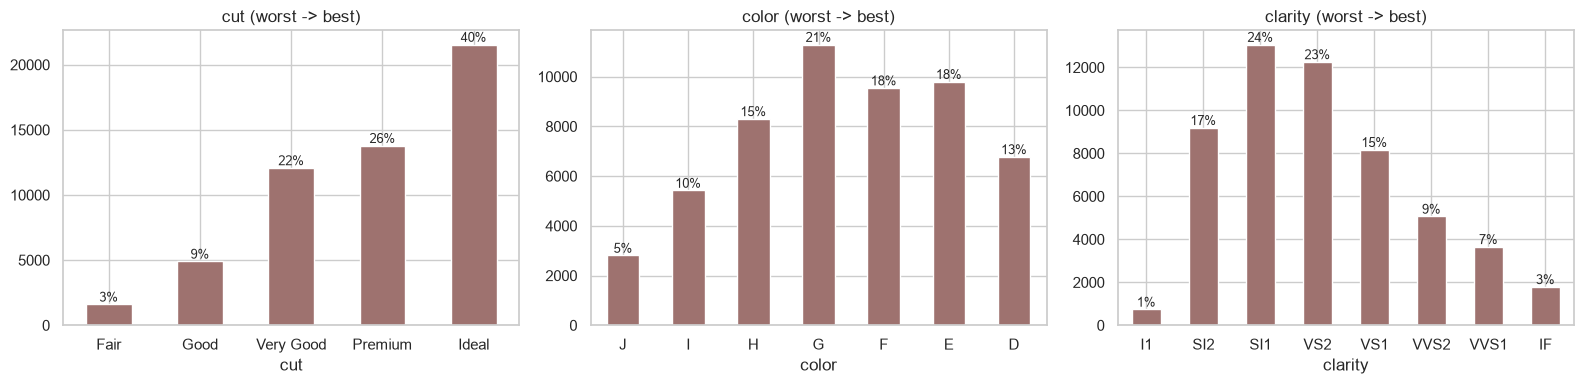

In [7]:
CUT_ORDER = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
COLOR_ORDER = ['J', 'I', 'H', 'G', 'F', 'E', 'D']
CLARITY_ORDER = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
ORDERS = {'cut': CUT_ORDER, 'color': COLOR_ORDER, 'clarity': CLARITY_ORDER}

f, ax = plt.subplots(1, 3, figsize=(16, 4))
for i, (col, order) in enumerate(ORDERS.items()):
    counts = data_df[col].value_counts().reindex(order)
    counts.plot.bar(ax=ax[i], rot=0, color='#9E726F')
    ax[i].set_title(f'{col} (worst -> best)')
    for j, v in enumerate(counts):
        ax[i].text(j, v, f'{v / len(data_df):.0%}', ha='center', va='bottom', fontsize=9)
plt.tight_layout(); plt.show()

**그림 읽기** (모두 왼쪽 = 나쁜 등급, 오른쪽 = 좋은 등급)
- `cut`: **Ideal이 40%** 로 가장 많고 Fair는 3%뿐입니다. 시장에 나온 다이아몬드는 대부분 잘 깎여 있습니다.
- `color`: 가운데 G가 가장 많고, 양 끝(J, D)은 적습니다.
- `clarity`: 중간 등급(SI1, VS2)이 대부분이고, 가장 나쁜 I1(1%)과 가장 좋은 IF(3%)는 드뭅니다.

> 원본 노트: "J 색(최하)이 가장 드물다", "IF와 I1이 매우 드물다" — 그림과 일치합니다.

---
# 3. 이상한 값 진단 — 비어 있지 않다고 깨끗한 것은 아니다

결측값은 없었지만 **값이 있어도 말이 안 되는 값**이 있을 수 있습니다. 세 가지를 확인합니다.
1. 크기가 **0**인 다이아몬드
2. 물리적으로 말이 안 되게 **큰** 크기
3. 완전히 똑같은 행(**중복**)

## 3-1 크기가 0인 행

In [8]:
zero = data_df[['x', 'y', 'z']] == 0
print('열별로 0인 행 수:', zero.sum().to_dict())
print('x, y, z 중 하나라도 0인 행:', zero.any(axis=1).sum(), '개')
data_df[zero.any(axis=1)].head(8)

열별로 0인 행 수: {'x': 8, 'y': 7, 'z': 20}
x, y, z 중 하나라도 0인 행: 20 개


,Unnamed: 0,carat,cut,color,clarity,depth,table,price,x,y,z
2207,2208,1.00,Premium,G,SI2,59.1,59.0,3142,6.55,6.48,0.0
2314,2315,1.01,Premium,H,I1,58.1,59.0,3167,6.66,6.60,0.0
4791,4792,1.10,Premium,G,SI2,63.0,59.0,3696,6.50,6.47,0.0
5471,5472,1.01,Premium,F,SI2,59.2,58.0,3837,6.50,6.47,0.0
10167,10168,1.50,Good,G,I1,64.0,61.0,4731,7.15,7.04,0.0
11182,11183,1.07,Ideal,F,SI2,61.6,56.0,4954,0.00,6.62,0.0
11963,11964,1.00,Very Good,H,VS2,63.3,53.0,5139,0.00,0.00,0.0
13601,13602,1.15,Ideal,G,VS2,59.2,56.0,5564,6.88,6.83,0.0


**결론:** 20개 행에서 크기가 0입니다. 그런데 `carat`(무게)과 `price`는 멀쩡히 있습니다.
무게가 1캐럿인 다이아몬드의 높이가 0 mm일 수는 없으므로 **측정값을 기록하지 못한 것**입니다.
53,940개 중 20개(0.04%)뿐이라 **지워도 손실이 거의 없습니다.** (원본과 같은 판단)

## 3-2 말이 안 되게 큰 크기

In [9]:
display(data_df.nlargest(3, 'y')[['carat', 'x', 'y', 'z', 'depth', 'price']])
display(data_df.nlargest(3, 'z')[['carat', 'x', 'y', 'z', 'depth', 'price']])

,carat,x,y,z,depth,price
24067,2.00,8.09,58.90,8.06,58.9,12210
49189,0.51,5.15,31.80,5.12,61.8,2075
27415,5.01,10.74,10.54,6.98,65.5,18018


,carat,x,y,z,depth,price
48410,0.51,5.12,5.15,31.80,61.8,1970
24067,2.00,8.09,58.90,8.06,58.9,12210
27415,5.01,10.74,10.54,6.98,65.5,18018


**확인:** 같은 행 안의 숫자끼리 비교하면 오류가 보입니다.
- `y = 58.9`인 다이아몬드: `x = 8.09`, `z = 8.06`인데 너비만 58.9 mm? 무게가 2캐럿이면 너비는 8 mm 정도가 정상입니다. → 아마 **5.89를 58.9로** 잘못 적은 것
- `z = 31.8`인 다이아몬드: 0.51캐럿인데 높이가 3cm? 0.51캐럿이면 높이는 3.2 mm 정도 → 아마 **3.18을 31.8로**
- 반면 5.01캐럿(가장 무거운 것)의 x = 10.74, y = 10.54는 무게에 맞는 크기라 **진짜 큰 다이아몬드**입니다.

> **이상값 ≠ 오류.** 큰 값이라고 무조건 지우는 것이 아니라, **다른 열과 비교해 말이 되는지** 확인해야 합니다.
> 5.01캐럿 다이아몬드는 드물지만 진짜이므로 남겨야 합니다.

## 3-3 `depth` 공식으로 검산하기

`depth`는 "높이 ÷ 평균 지름 × 100"으로 **계산되는** 값입니다. 그렇다면 `z / ((x + y) / 2) × 100`을 직접 계산해서
기록된 `depth`와 비교하면 오류 행을 찾을 수 있습니다.

직접 계산한 depth와 기록된 depth의 차이
  중앙값: 0.027  → 대부분 거의 똑같음 (반올림 차이)
  차이가  1 이상인 행: 80개
  차이가  5 이상인 행: 27개
  차이가 10 이상인 행: 19개


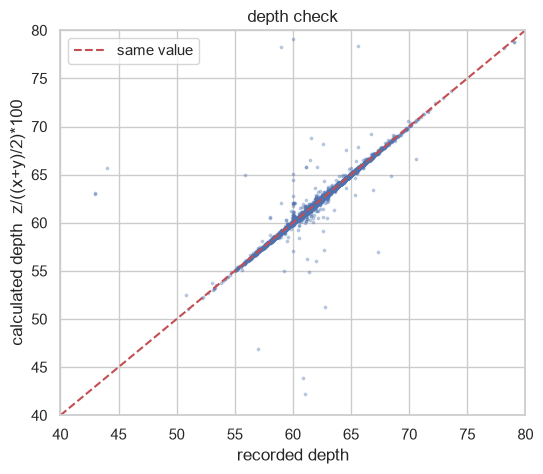

In [10]:
ok = ~zero.any(axis=1)
calc_depth = data_df.loc[ok, 'z'] / ((data_df.loc[ok, 'x'] + data_df.loc[ok, 'y']) / 2) * 100
gap = (calc_depth - data_df.loc[ok, 'depth']).abs()

print('직접 계산한 depth와 기록된 depth의 차이')
print(f'  중앙값: {gap.median():.3f}  → 대부분 거의 똑같음 (반올림 차이)')
for t in [1, 5, 10]:
    print(f'  차이가 {t:>2} 이상인 행: {(gap > t).sum()}개')

f, ax = plt.subplots(figsize=(6, 5))
ax.scatter(data_df.loc[ok, 'depth'], calc_depth, s=3, alpha=0.3)
ax.plot([40, 80], [40, 80], 'r--', label='same value')
ax.set_xlim(40, 80); ax.set_ylim(40, 80)
ax.set_xlabel('recorded depth'); ax.set_ylabel('calculated depth  z/((x+y)/2)*100')
ax.set_title('depth check'); ax.legend(); plt.show()

**결론:** 대부분의 점이 빨간 대각선(두 값이 같음) 위에 있습니다 → 데이터가 대체로 **계산과 맞는다**는 뜻입니다.
대각선에서 크게 벗어난 소수의 행은 x, y, z 중 하나가 잘못 기록된 것입니다.
8장에서 확인하겠지만, 원본의 크기 범위 규칙(x, y, z < 40)으로는 **y = 31.8, z = 31.8 같은 행이 걸러지지 않습니다.**
그래서 이 검산 결과(차이 5 이상)를 정리 규칙에 추가합니다.

> 원본은 그림을 눈으로 보고 기준을 정했지만, 이렇게 **열 사이의 관계(공식)** 를 이용하면 오류를 더 확실하게 찾을 수 있습니다.

## 3-4 완전히 똑같은 행 (중복)

In [11]:
no_index = data_df.drop(columns=['Unnamed: 0'], errors='ignore')
dup = no_index.duplicated(keep=False)
print('행 번호를 빼고 모든 값이 똑같은 행:', no_index.duplicated().sum(), '개 (첫 번째는 원본으로 보고, 나머지를 중복으로 셈)')
no_index[dup].sort_values(list(no_index.columns)).head(6)

행 번호를 빼고 모든 값이 똑같은 행: 146 개 (첫 번째는 원본으로 보고, 나머지를 중복으로 셈)


,carat,cut,color,clarity,depth,table,price,x,y,z
43995,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
47296,0.3,Good,J,VS1,63.4,57.0,394,4.23,4.26,2.69
34408,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
34422,0.3,Ideal,G,IF,62.1,55.0,863,4.32,4.35,2.69
28592,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71
28593,0.3,Ideal,G,VS2,63.0,55.0,675,4.31,4.29,2.71


**결론:** 무게·등급·크기·가격까지 **10개 열이 전부 같은** 행이 146개 있습니다. 같은 다이아몬드가 두 번 기록되었을 가능성이 큽니다.

> **중복이 왜 문제인가?** 데이터를 학습용과 시험용으로 나눌 때, 같은 다이아몬드가 양쪽에 하나씩 들어가면
> 모델은 시험에서 **이미 본 문제**를 푸는 셈이 됩니다. 점수가 실제보다 좋게 나옵니다. 원본은 중복을 확인하지 않았으므로 8장에서 지웁니다.

| 문제 | 개수 | 처리 |
|---|---|---|
| 크기가 0 | 20행 | 삭제 (원본과 같음) |
| 말이 안 되는 크기 (y = 58.9 등) | 몇 행 | 원본 규칙으로 삭제 (8장) |
| depth 공식과 맞지 않음 (y = 31.8, z = 31.8 포함) | 20여 행 | 공식 검산으로 삭제 **(원본에 추가)** (8장) |
| 완전 중복 | 146행 | 삭제 **(원본에 추가)** |

---
# 4. 목표변수(price) 살펴보기

## 4-1 가격의 분포

**가설:** 비싼 다이아몬드는 드무니 가격은 낮은 쪽에 몰리고 오른쪽으로 긴 꼬리를 가질 것이다.

최소 326  |  중앙값 2,401  |  평균 3,933  |  최대 18,823
치우침 정도(skew): 원래 가격 1.62  /  로그 가격 0.12   (0에 가까울수록 좌우 대칭)


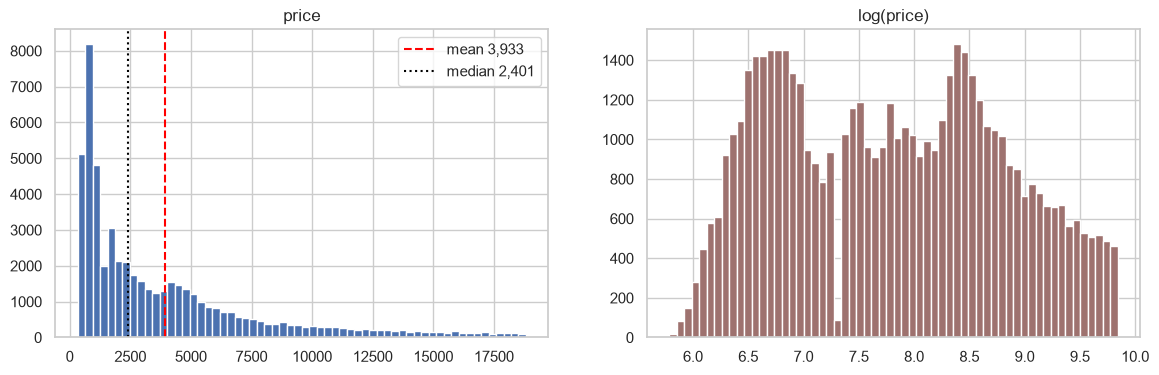

In [12]:
price = data_df['price']
print(f'최소 {price.min():,}  |  중앙값 {price.median():,.0f}  |  평균 {price.mean():,.0f}  |  최대 {price.max():,}')
print(f'치우침 정도(skew): 원래 가격 {price.skew():.2f}  /  로그 가격 {np.log(price).skew():.2f}   (0에 가까울수록 좌우 대칭)')

f, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].hist(price, bins=60, edgecolor='white')
ax[0].axvline(price.mean(), color='red', linestyle='--', label=f'mean {price.mean():,.0f}')
ax[0].axvline(price.median(), color='black', linestyle=':', label=f'median {price.median():,.0f}')
ax[0].set_title('price'); ax[0].legend()
ax[1].hist(np.log(price), bins=60, edgecolor='white', color='#9E726F')
ax[1].set_title('log(price)')
plt.show()

**그림 읽기**
- 왼쪽(원래 가격): 1,000달러 근처에 가장 많고 오른쪽으로 길게 늘어집니다. 원본 노트의 "가격은 오른쪽으로 치우쳐 있다(right skewed)"와 같습니다.
- 오른쪽(**로그** 가격): 훨씬 좌우가 고른 모양입니다.

> **로그(log)란?** 곱하기를 더하기로 바꾸는 계산입니다. 1,000 → 10,000(10배)과 10,000 → 100,000(10배)을 **같은 간격**으로 보여 줍니다.
> 가격처럼 "몇 배 차이"가 중요한 값에 잘 맞습니다. 10장에서 로그 가격으로 모델을 만들면 성능이 크게 좋아지는 것을 확인합니다.

## 4-2 회귀 문제의 채점 기준 — RMSE, MAE, R²

분류(타이타닉)는 "맞았다/틀렸다"를 세서 정확도를 냈습니다. 회귀는 정답과 예측이 모두 숫자라서 **얼마나 차이 나는지(오차)** 를 봅니다.

| 지표 | 계산 방법 | 뜻 | 좋은 값 |
|---|---|---|---|
| **MAE** (평균 절대 오차) | \|정답 − 예측\| 의 평균 | "평균적으로 몇 달러 틀리나" | 작을수록 |
| **RMSE** (평균 제곱근 오차) | (정답 − 예측)² 의 평균에 √ | MAE와 비슷하지만 **크게 틀린 것에 더 큰 벌점** | 작을수록 |
| **R²** (결정계수) | 1 − (모델의 오차² 합 ÷ 평균만 찍었을 때 오차² 합) | "평균으로만 찍는 것보다 얼마나 나아졌나" | 1에 가까울수록 |

### 손으로 계산해 보기 — 다이아몬드 4개

In [13]:
toy = pd.DataFrame({'정답 가격': [1000, 2000, 3000, 10000],
                    '예측 가격': [1200, 1800, 3500, 8000]})
toy['오차'] = toy['정답 가격'] - toy['예측 가격']
toy['|오차|'] = toy['오차'].abs()
toy['오차²'] = toy['오차'] ** 2
display(toy)

mae = toy['|오차|'].mean()
rmse = np.sqrt(toy['오차²'].mean())
mean_guess_sq = ((toy['정답 가격'] - toy['정답 가격'].mean()) ** 2).sum()
r2 = 1 - toy['오차²'].sum() / mean_guess_sq
print(f'MAE  = (200 + 200 + 500 + 2000) / 4 = {mae:,.0f}')
print(f'RMSE = √((40,000 + 40,000 + 250,000 + 4,000,000) / 4) = {rmse:,.0f}')
print(f'R²   = 1 - {toy["오차²"].sum():,} / {mean_guess_sq:,.0f} = {r2:.3f}')

,정답 가격,예측 가격,오차,|오차|,오차²
0,1000,1200,-200,200,40000
1,2000,1800,200,200,40000
2,3000,3500,-500,500,250000
3,10000,8000,2000,2000,4000000


MAE  = (200 + 200 + 500 + 2000) / 4 = 725
RMSE = √((40,000 + 40,000 + 250,000 + 4,000,000) / 4) = 1,040
R²   = 1 - 4,330,000 / 50,000,000 = 0.913


**읽는 법**
- MAE는 725달러, RMSE는 1,040달러입니다. 2,000달러를 틀린 **하나** 때문에 RMSE가 MAE보다 훨씬 큽니다. RMSE는 **큰 실수를 싫어하는** 지표입니다.
- R² = 0.91 → "평균 가격(4,000달러)으로만 찍었을 때의 오차(제곱 합)를 91% 줄였다"는 뜻입니다.

> **[원본 수정]** 원본 마지막 문장 "We got 98.27% **accuracy**"는 정확한 표현이 아닙니다. 98.27%는 **R²** 입니다.
> R² = 0.98은 "가격의 98%를 맞혔다"가 아니라 "평균으로 찍는 것보다 오차(의 제곱)를 98% 줄였다"는 뜻입니다.
> 실제로 몇 달러, 몇 % 틀리는지는 RMSE·MAE로 따로 확인해야 합니다(12장).

## 4-3 기준선(baseline) — 아무것도 배우지 않은 답안

모든 다이아몬드를 **평균 가격**으로 찍으면 점수가 얼마일까요? 앞으로 만드는 모델은 이 점수보다 **훨씬** 좋아야 의미가 있습니다.

In [14]:
base = np.full(len(price), price.mean())
print(f'모두 평균({price.mean():,.0f}달러)으로 찍을 때')
print(f'  RMSE = {np.sqrt(((price - base) ** 2).mean()):,.0f}달러   ← 가격의 표준편차와 같음')
print(f'  MAE  = {(price - base).abs().mean():,.0f}달러')
print(f'  R²   = 0  (정의상 평균으로 찍으면 R² = 0)')

모두 평균(3,933달러)으로 찍을 때
  RMSE = 3,989달러   ← 가격의 표준편차와 같음
  MAE  = 3,032달러
  R²   = 0  (정의상 평균으로 찍으면 R² = 0)


**기준선: RMSE 약 3,989달러, MAE 약 3,032달러.** 평균 가격이 3,933달러이니, 평균으로 찍으면 거의 가격만큼 틀립니다.

---
# 5. 수치형 변수와 가격

## 5-1 무게 (carat)

**가설:** 무거울수록 비싸다. 그런데 2캐럿이 1캐럿의 **2배** 가격일까, 그 이상일까?

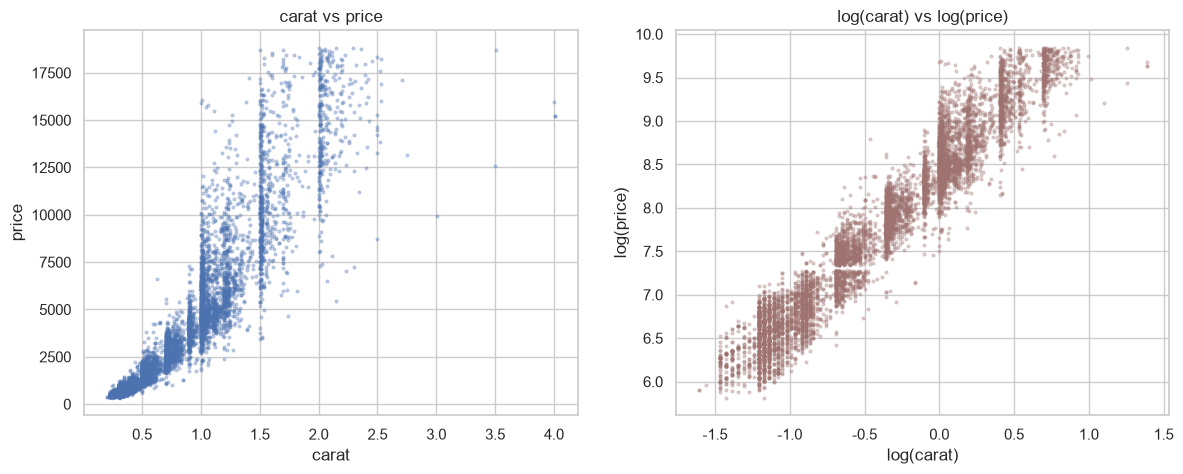

carat과 price의 상관계수          : 0.922
log(carat)과 log(price)의 상관계수: 0.966


In [15]:
sample = data_df.sample(8000, random_state=SEED)   # 점이 너무 많으면 그림이 뭉개지므로 일부만 그립니다

f, ax = plt.subplots(1, 2, figsize=(14, 5))
ax[0].scatter(sample['carat'], sample['price'], s=4, alpha=0.3)
ax[0].set_xlabel('carat'); ax[0].set_ylabel('price'); ax[0].set_title('carat vs price')
ax[1].scatter(np.log(sample['carat']), np.log(sample['price']), s=4, alpha=0.3, color='#9E726F')
ax[1].set_xlabel('log(carat)'); ax[1].set_ylabel('log(price)'); ax[1].set_title('log(carat) vs log(price)')
plt.show()

print('carat과 price의 상관계수          :', round(data_df['carat'].corr(data_df['price']), 3))
print('log(carat)과 log(price)의 상관계수:', round(np.log(data_df['carat']).corr(np.log(data_df['price'])), 3))

**그림 읽기**
- 왼쪽: 무게가 늘수록 가격이 오르지만 **직선이 아니라 위로 휘는 곡선**입니다. 무게가 커질수록 가격이 더 가파르게 오릅니다.
  또한 무게가 커질수록 점이 위아래로 **넓게 퍼집니다** (같은 2캐럿이라도 등급에 따라 가격 차이가 큼).
- 오른쪽: 양쪽에 로그를 씌우면 **거의 곧은 직선**이 되고, 퍼짐도 고르게 됩니다. 상관계수도 0.92 → 0.97로 커집니다.

> **왜 중요한가?** `LinearRegression`(선형 회귀)은 **직선**을 긋는 모델입니다. 휜 관계에 직선을 그으면 잘 맞지 않습니다.
> 로그를 씌워 관계를 곧게 펴 주면 단순한 직선 모델도 잘 맞습니다(10장에서 확인).

### 무게의 "인기 숫자"

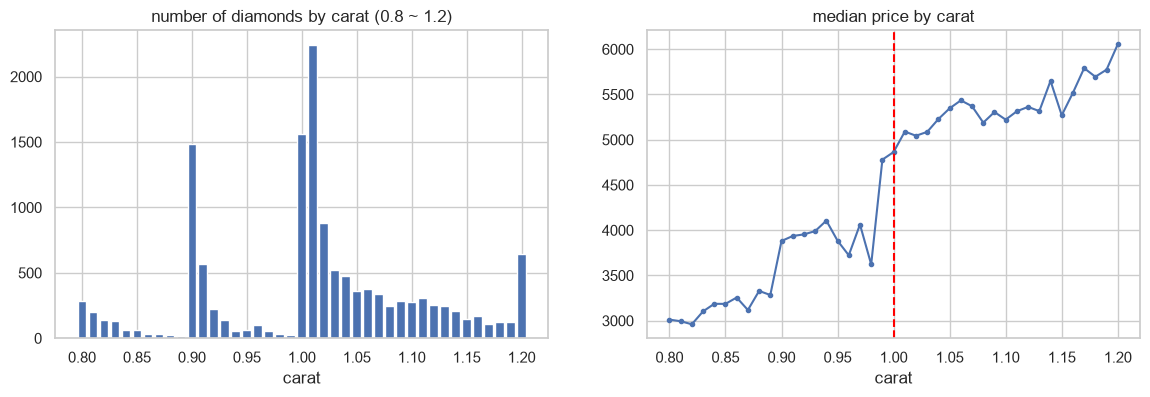

0.99캐럿: 23 개  |  1.00캐럿: 1558 개  |  1.01캐럿: 2242 개
가격 중앙값: 0.95~0.99캐럿 3,918달러  →  1.00~1.04캐럿 5,038달러  (29% 상승)


In [16]:
fine = data_df[(data_df['carat'] >= 0.8) & (data_df['carat'] <= 1.2)]
counts = fine['carat'].value_counts().sort_index()
f, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(counts.index, counts.values, width=0.008)
ax[0].set_title('number of diamonds by carat (0.8 ~ 1.2)'); ax[0].set_xlabel('carat')
med = fine.groupby('carat')['price'].median()
ax[1].plot(med.index, med.values, marker='o', ms=3)
ax[1].axvline(1.0, color='red', linestyle='--')
ax[1].set_title('median price by carat'); ax[1].set_xlabel('carat')
plt.show()
print('0.99캐럿:', counts.get(0.99, 0), '개  |  1.00캐럿:', counts.get(1.00, 0), '개  |  1.01캐럿:', counts.get(1.01, 0), '개')
below = fine.loc[fine['carat'].between(0.95, 0.99), 'price'].median()
above = fine.loc[fine['carat'].between(1.00, 1.04), 'price'].median()
print(f'가격 중앙값: 0.95~0.99캐럿 {below:,.0f}달러  →  1.00~1.04캐럿 {above:,.0f}달러  ({above / below - 1:.0%} 상승)')

**발견:** 1.00캐럿과 1.01캐럿에 다이아몬드가 몰려 있고, 0.99캐럿은 거의 없습니다. 가격도 **1캐럿을 넘는 순간 훌쩍 뜁니다.**
무게는 5% 정도 차이인데 가격 중앙값은 약 29% 높습니다. 사람들이 "1캐럿 다이아몬드"를 원하기 때문에, 원석을 깎을 때 1캐럿을 살짝 넘기도록 깎는 것입니다.
**데이터에는 사람의 행동이 묻어 있습니다.** 나무 모델(의사결정나무, 랜덤 포레스트)은 이런 "계단"을 잘 잡아냅니다.

## 5-2 크기 (x, y, z) — 무게와 같은 정보일까?

**가설:** 무게 = 부피 × 밀도이고, 부피는 대략 x × y × z에 비례한다. 따라서 x, y, z는 무게와 거의 같은 정보일 것이다.

,carat,x,y,z,price
carat,1.000,0.978,0.977,0.976,0.922
x,0.978,1.000,0.999,0.991,0.887
y,0.977,0.999,1.000,0.991,0.889
z,0.976,0.991,0.991,1.000,0.882
price,0.922,0.887,0.889,0.882,1.000


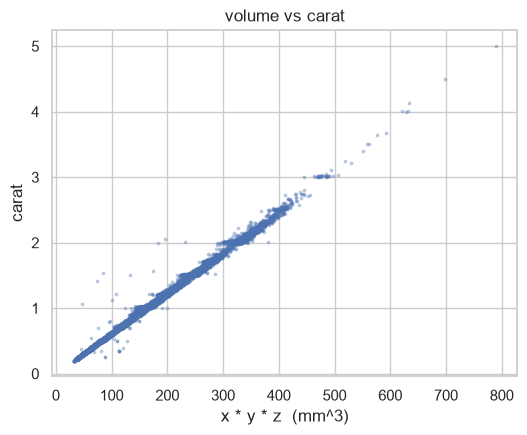

부피(x*y*z)와 carat의 상관계수: 0.9989


In [17]:
clean_xyz = data_df[(data_df[['x', 'y', 'z']] > 0).all(axis=1) & (data_df['y'] < 20) & (data_df['z'] < 20)]
display(clean_xyz[['carat', 'x', 'y', 'z', 'price']].corr().round(3))

volume = clean_xyz['x'] * clean_xyz['y'] * clean_xyz['z']
plt.figure(figsize=(6, 4.5))
plt.scatter(volume, clean_xyz['carat'], s=3, alpha=0.3)
plt.xlabel('x * y * z  (mm^3)'); plt.ylabel('carat'); plt.title('volume vs carat')
plt.show()
print('부피(x*y*z)와 carat의 상관계수:', round(volume.corr(clean_xyz['carat']), 4))

**결론:** 부피와 무게의 상관계수가 0.999에 가깝습니다. **x, y, z는 무게(carat)를 다른 단위로 다시 적은 것**과 거의 같습니다.
그래서 x, y, z와 price의 상관(0.86~0.89)이 carat과 price의 상관(0.92)과 비슷하게 높습니다.

> 원본 노트: "carat, x, y, z가 가격과 상관이 높다" — 맞습니다. 다만 이 넷은 **사실상 같은 정보 한 가지**입니다.
> 서로 거의 같은 열이 여러 개 있으면 선형 회귀의 계수(각 열의 영향력)를 해석하기 어려워집니다. 예측 점수 자체에는 큰 문제가 없습니다.

## 5-3 모양 비율 (depth, table) — 원본의 lmplot

원본은 가격과 `y`, `z`, `depth`, `table`의 관계를 `lmplot`(점 + 직선)으로 그려 이상값을 찾았습니다. 네 그림을 한 번에 그립니다.

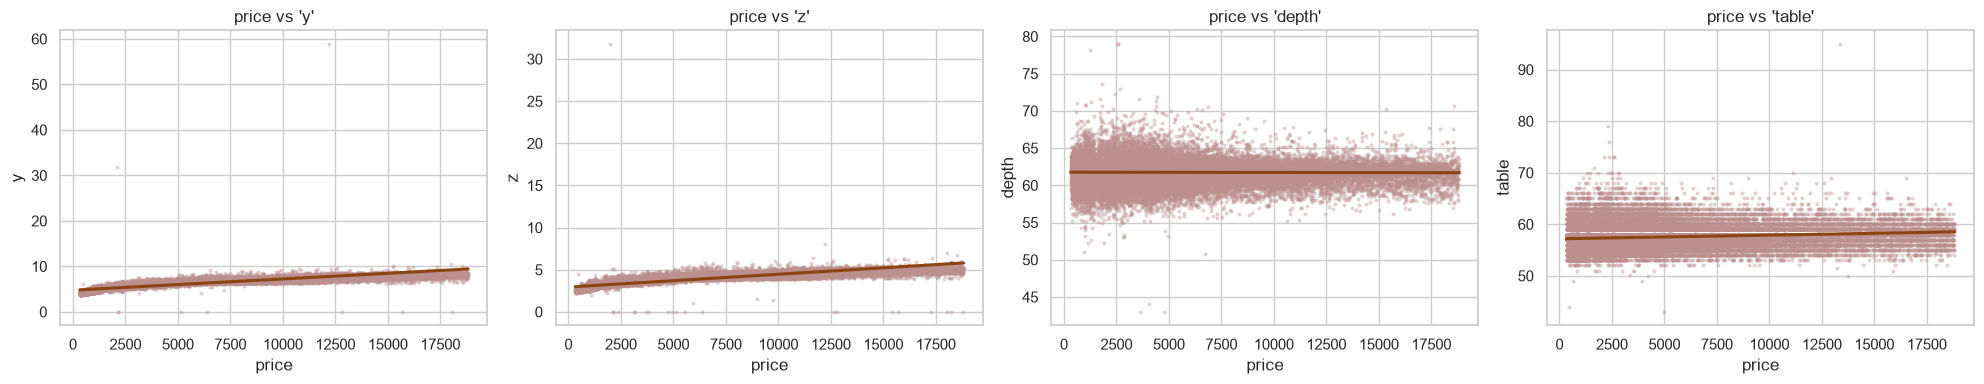

In [18]:
# 원본: sns.lmplot(x="price", y=...)을 4번 그림 → 한 화면에 모아서 그림
f, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, col in zip(axes, ['y', 'z', 'depth', 'table']):
    sns.regplot(x='price', y=col, data=data_df, ax=ax,
                scatter_kws={'color': '#BC8F8F', 's': 4, 'alpha': 0.3}, line_kws={'color': '#8B4513'})
    ax.set_title(f"price vs '{col}'")
plt.tight_layout(); plt.show()

**그림 읽기** (원본 노트와 같은 관찰)
- `y`, `z`: 대부분 아래쪽 띠에 있고, 위로 동떨어진 점 몇 개(58.9, 31.8 등)와 0인 점이 있습니다 → 3장에서 찾은 기록 오류
- `depth`: 대부분 55~70 사이에 몰려 있고, 43이나 79 같은 점은 동떨어져 있습니다.
- `table`: 대부분 50~65 사이, 95 같은 점은 동떨어져 있습니다.

> 이상값 몇 개 때문에 축 범위가 넓어져서 정작 대부분의 데이터가 **납작하게** 보입니다. 이것도 이상값을 정리하는 이유 중 하나입니다.

**가설:** depth와 table은 가격과 관계가 거의 없을 것이다.

depth   -0.011
table    0.127
price    1.000
Name: price, dtype: float64


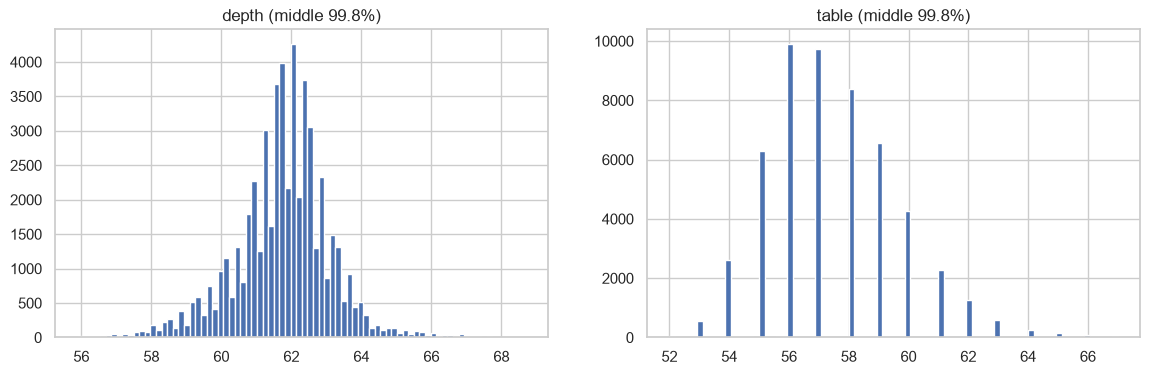

In [19]:
print(data_df[['depth', 'table', 'price']].corr().round(3)['price'])

f, ax = plt.subplots(1, 2, figsize=(14, 4))
for i, col in enumerate(['depth', 'table']):
    ax[i].hist(data_df[col], bins=80, range=data_df[col].quantile([0.001, 0.999]).tolist(), edgecolor='white')
    ax[i].set_title(f'{col} (middle 99.8%)')
plt.show()

**결론:** `depth`와 가격의 상관은 −0.01, `table`은 0.13으로 **거의 관계가 없습니다.** 두 값 모두 아주 좁은 범위에 몰려 있습니다.
시장에 나온 다이아몬드는 대부분 비슷한 비율로 깎기 때문입니다. 모델에 넣어도 큰 도움은 안 될 것입니다(13장에서 확인).

---
# 6. 범주형 변수와 가격 — "나쁜 등급이 더 비싸다?"

## 6-1 원본의 바이올린 그림

**가설:** 좋은 등급(Ideal 컷, D 색, IF 투명도)일수록 가격이 높을 것이다.

> **바이올린 그림**: 상자 그림(box plot)의 양옆에 **분포의 모양**을 그려 넣은 그림입니다. 넓은 곳에 데이터가 많습니다.

**[원본 수정]** seaborn 0.13부터 `scale="count"`는 `density_norm="count"`로 바뀌었고, `hue` 없이 `palette`만 주면 경고가 납니다.
또 원본은 등급이 **글자 순서(알파벳)** 로 섞여 그려졌습니다. 여기서는 `order=`로 **나쁨 → 좋음** 순서를 지정합니다.

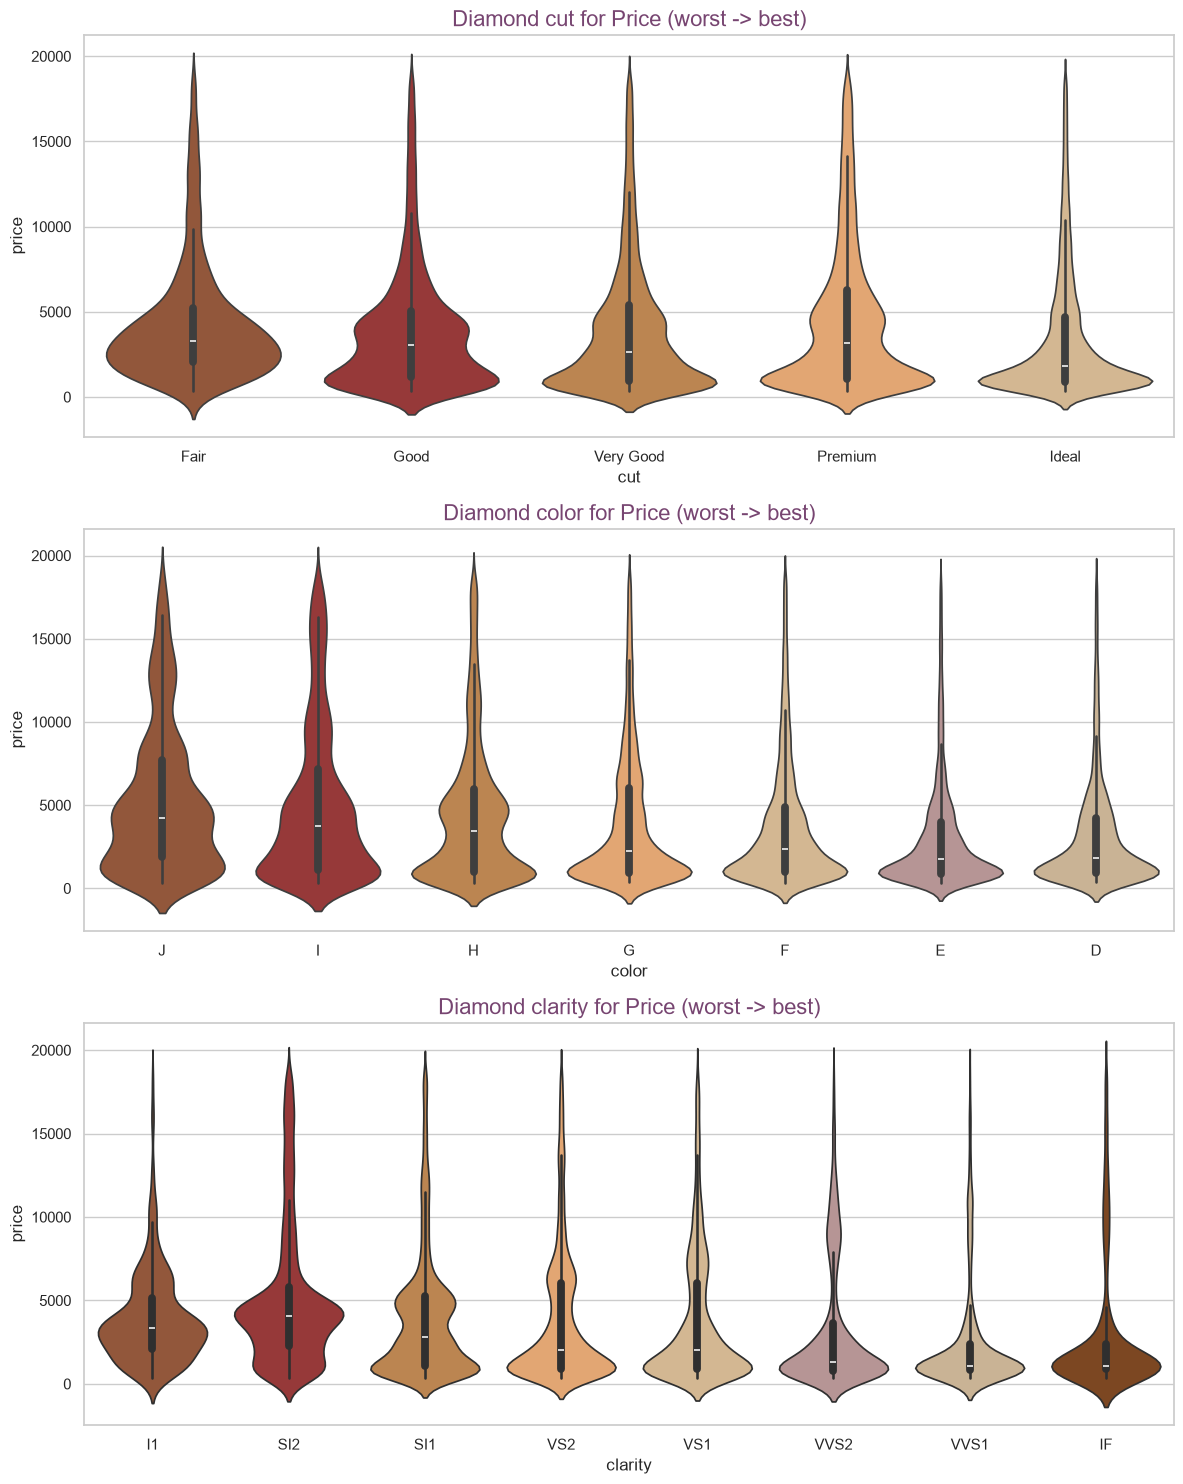

In [20]:
cols = ['#A0522D', '#A52A2A', '#CD853F', '#F4A460', '#DEB887', '#BC8F8F', '#D2B48C', '#8B4513']
f, axes = plt.subplots(3, 1, figsize=(12, 15))
for ax, (col, order) in zip(axes, ORDERS.items()):
    sns.violinplot(x=col, y='price', data=data_df, order=order, hue=col, hue_order=order,
                   palette=cols[:len(order)], density_norm='count', legend=False, ax=ax)
    ax.set_title(f'Diamond {col} for Price (worst -> best)', color='#774571', fontsize=16)
plt.tight_layout(); plt.show()

**이상합니다.** 좋은 등급으로 갈수록 가격이 올라가야 하는데, 그림에서는 그렇지 않습니다. 숫자로 확인해 봅니다.

## 6-2 등급별 가격 중앙값 — 역설 발견

cut      {'Fair': 3282, 'Good': 3050, 'Very Good': 2648, 'Premium': 3185, 'Ideal': 1810}
color    {'J': 4234, 'I': 3730, 'H': 3460, 'G': 2242, 'F': 2344, 'E': 1739, 'D': 1838}
clarity  {'I1': 3344, 'SI2': 4072, 'SI1': 2822, 'VS2': 2054, 'VS1': 2005, 'VVS2': 1311, 'VVS1': 1093, 'IF': 1080}


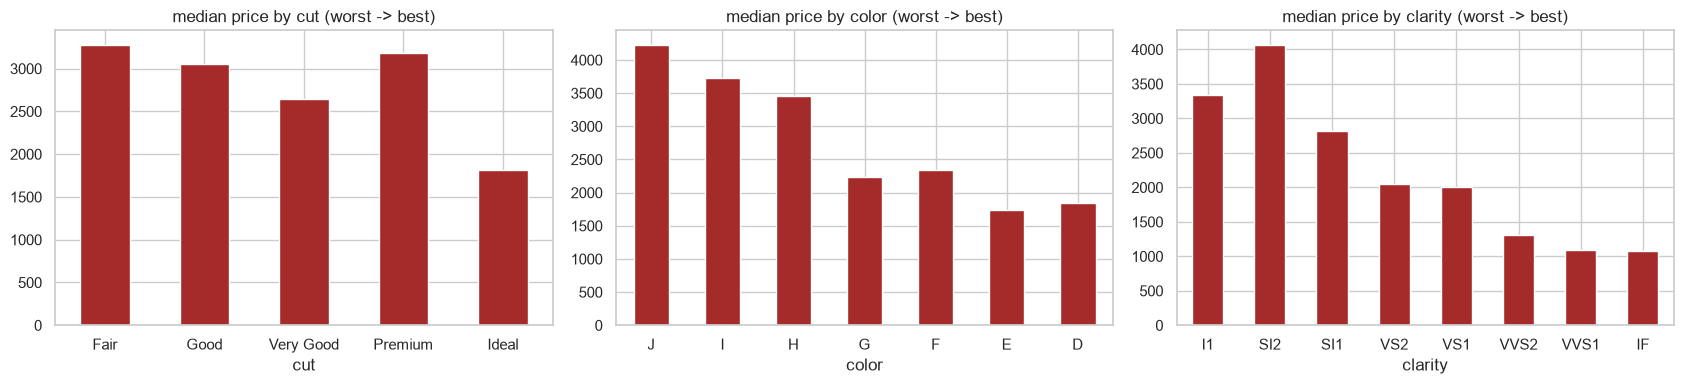

In [21]:
def by_grade(col, data=None, value='price'):
    data = data_df if data is None else data
    return data.groupby(col)[value].median().reindex(ORDERS[col])

f, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, col in enumerate(ORDERS):
    s = by_grade(col)
    s.plot.bar(ax=ax[i], rot=0, color='#A52A2A')
    ax[i].set_title(f'median price by {col} (worst -> best)')
    print(f'{col:8s}', s.round(0).astype(int).to_dict())
plt.tight_layout(); plt.show()

**역설:** 가설과 **정반대**입니다.

| 열 | 가장 나쁜 등급의 가격 중앙값 | 가장 좋은 등급의 가격 중앙값 |
|---|---|---|
| `cut` | Fair **3,282** | Ideal **1,810** |
| `color` | J **4,234** | D **1,838** |
| `clarity` | I1 **3,344** | IF **1,080** |

가장 좋은 투명도(IF)의 가격이 가장 나쁜 투명도(I1)의 **3분의 1**입니다. 정말 흠 있는 다이아몬드가 더 비싼 걸까요?

## 6-3 범인 찾기 — 등급별 **무게**

**가설:** 등급이 나쁜 다이아몬드가 **더 무거운** 것 아닐까? 5장에서 무게가 가격을 가장 크게 좌우한다는 것을 보았다.

cut      {'Fair': 1.0, 'Good': 0.82, 'Very Good': 0.71, 'Premium': 0.86, 'Ideal': 0.54}
color    {'J': 1.11, 'I': 1.0, 'H': 0.9, 'G': 0.7, 'F': 0.7, 'E': 0.53, 'D': 0.53}
clarity  {'I1': 1.12, 'SI2': 1.01, 'SI1': 0.76, 'VS2': 0.63, 'VS1': 0.57, 'VVS2': 0.44, 'VVS1': 0.39, 'IF': 0.35}


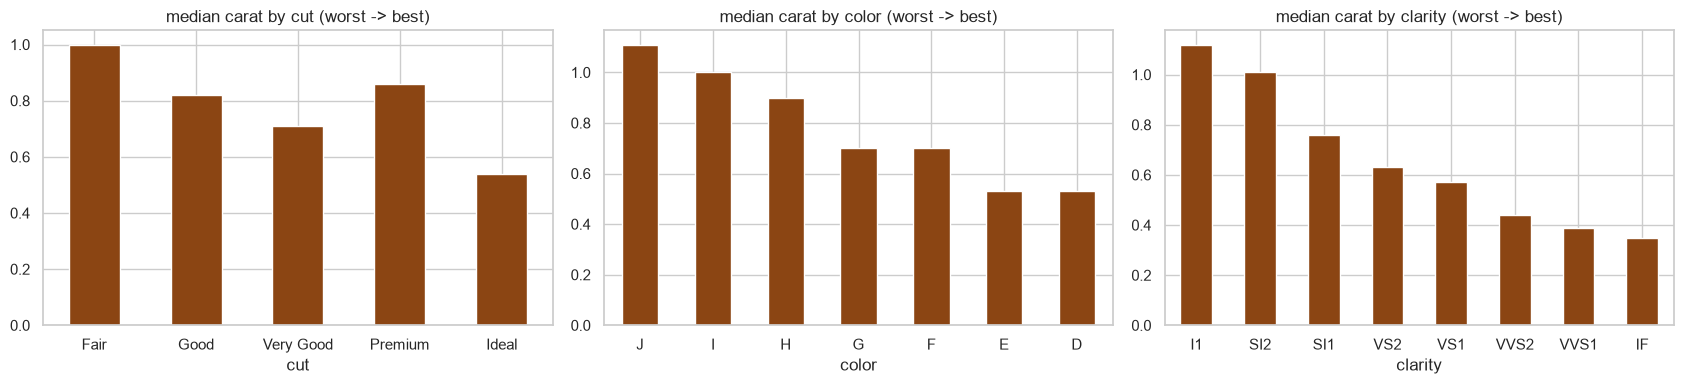

In [22]:
f, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, col in enumerate(ORDERS):
    s = by_grade(col, value='carat')
    s.plot.bar(ax=ax[i], rot=0, color='#8B4513')
    ax[i].set_title(f'median carat by {col} (worst -> best)')
    print(f'{col:8s}', s.round(2).to_dict())
plt.tight_layout(); plt.show()

**찾았습니다.** 나쁜 등급일수록 **무게 중앙값이 큽니다.** (I1: 1.12캐럿, IF: 0.35캐럿 / J: 1.11캐럿, D: 0.53캐럿)

왜 그럴까요? 큰 원석은 흠이 있거나 색이 조금 있어도 **크기만으로 충분히 비싸게** 팔 수 있어서 시장에 나옵니다.
반면 작은 원석은 등급이 좋아야 팔 가치가 있습니다. 결과적으로 "나쁜 등급 = 큰 다이아몬드"가 많아졌습니다.

```
  나쁜 등급 ──(함께 나타남)──▶ 무거운 무게 ──(직접 원인)──▶ 비싼 가격
```

나쁜 등급이 비싸게 **보이는** 것은 등급 때문이 아니라, **그 뒤에 숨은 무게 때문**입니다.
타이타닉의 "탑승 항구 → 생존률" 차이가 사실은 항구별 객실 등급 구성 차이였던 것과 같은 구조입니다.

## 6-4 공정하게 비교하기 — **같은 무게끼리**

**가설:** 무게를 비슷하게 맞추고 비교하면 원래 예상대로 좋은 등급이 더 비쌀 것이다.

0.9 ~ 1.1캐럿 다이아몬드만: 10,331개
cut      {'Fair': 3730, 'Good': 4312, 'Very Good': 4691, 'Premium': 4670, 'Ideal': 5220}
color    {'J': 3599, 'I': 3960, 'H': 4513, 'G': 5236, 'F': 4917, 'E': 4921, 'D': 5080}
clarity  {'I1': 2666, 'SI2': 4065, 'SI1': 4679, 'VS2': 5800, 'VS1': 6402, 'VVS2': 8361, 'VVS1': 8398, 'IF': 10056}


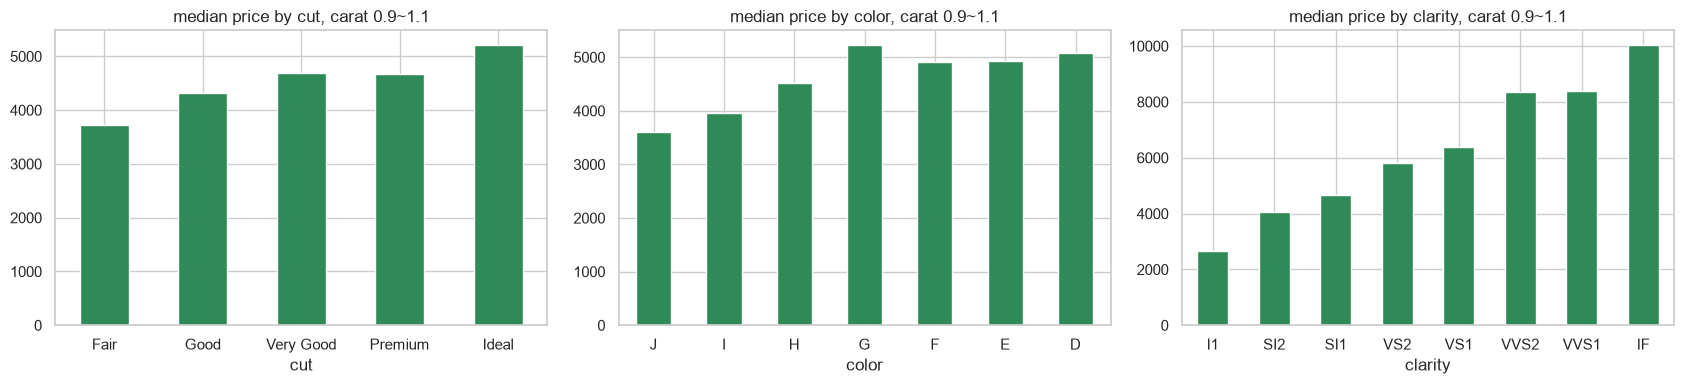

In [23]:
one_carat = data_df[(data_df['carat'] >= 0.9) & (data_df['carat'] <= 1.1)]
print(f'0.9 ~ 1.1캐럿 다이아몬드만: {len(one_carat):,}개')

f, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, col in enumerate(ORDERS):
    s = by_grade(col, data=one_carat)
    s.plot.bar(ax=ax[i], rot=0, color='#2E8B57')
    ax[i].set_title(f'median price by {col}, carat 0.9~1.1')
    print(f'{col:8s}', s.round(0).astype(int).to_dict())
plt.tight_layout(); plt.show()

**결론:** 무게를 1캐럿 근처로 맞추니 **원래 예상한 방향**이 나타납니다.
- `clarity`: I1 약 2,700 → IF 약 10,000달러. **약 4배** 차이로 가장 뚜렷합니다.
- `color`: J 약 3,600 → D~G 약 5,000달러. 좋은 색일수록 비쌉니다(D~G 사이는 비슷).
- `cut`: Fair 약 3,700 → Ideal 약 5,200달러. 좋은 컷이 비싸지만 차이는 셋 중 가장 작습니다.

이것을 한눈에 보기 위해 무게 구간 × 투명도 표를 만듭니다.

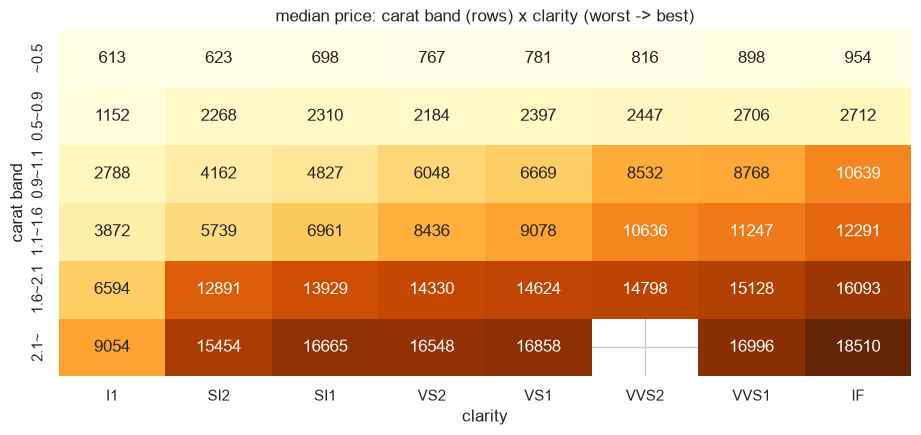

In [24]:
carat_band = pd.cut(data_df['carat'], [0, 0.5, 0.9, 1.1, 1.6, 2.1, 5.1],
                    labels=['~0.5', '0.5~0.9', '0.9~1.1', '1.1~1.6', '1.6~2.1', '2.1~'])
table_cl = data_df.pivot_table(index=carat_band, columns='clarity', values='price',
                               aggfunc='median', observed=True)[CLARITY_ORDER]
plt.figure(figsize=(11, 4.5))
sns.heatmap(table_cl, annot=True, fmt='.0f', cmap='YlOrBr', cbar=False)
plt.title('median price: carat band (rows) x clarity (worst -> best)'); plt.ylabel('carat band'); plt.show()

**표 읽기:** **한 줄(같은 무게 구간) 안에서** 왼쪽 → 오른쪽으로 가면 가격이 대체로 올라갑니다(좋은 투명도 = 비쌈).
**위 → 아래로** 가면 가격이 크게 올라갑니다(무거움 = 비쌈). 두 효과가 모두 있습니다.

> **이 장의 핵심 교훈**
> 1. 한 변수만 보고 결론을 내리면 **정반대의 결론**에 도달할 수 있습니다.
> 2. "A가 높을수록 B가 높다"는 관계 뒤에 **숨은 제3의 변수**(여기서는 무게)가 있는지 항상 의심합니다.
> 3. 공정한 비교는 **다른 조건을 같게 맞춘 뒤**에 합니다.

---
# 7. 글자를 숫자로 — 원본 LabelEncoder의 함정

## 7-1 원본 방식: `LabelEncoder`

모델은 글자를 계산할 수 없어 숫자로 바꿔야 합니다. 원본은 `LabelEncoder`를 썼습니다. 어떤 숫자가 붙는지 확인해 봅니다.

In [25]:
from sklearn.preprocessing import LabelEncoder

for col in ORDERS:
    le = LabelEncoder().fit(data_df[col])
    print(f'{col:8s}', dict(zip(le.classes_, le.transform(le.classes_))))

cut      {'Fair': np.int64(0), 'Good': np.int64(1), 'Ideal': np.int64(2), 'Premium': np.int64(3), 'Very Good': np.int64(4)}
color    {'D': np.int64(0), 'E': np.int64(1), 'F': np.int64(2), 'G': np.int64(3), 'H': np.int64(4), 'I': np.int64(5), 'J': np.int64(6)}
clarity  {'I1': np.int64(0), 'IF': np.int64(1), 'SI1': np.int64(2), 'SI2': np.int64(3), 'VS1': np.int64(4), 'VS2': np.int64(5), 'VVS1': np.int64(6), 'VVS2': np.int64(7)}


**[원본 수정] 문제 발견:** `LabelEncoder`는 **알파벳 순서**로 번호를 붙입니다.

| 열 | LabelEncoder 번호 (알파벳 순) | 실제 품질 순서 |
|---|---|---|
| `cut` | Fair=0, Good=1, **Ideal=2**, Premium=3, Very Good=4 | Fair < Good < Very Good < Premium < **Ideal** |
| `clarity` | **I1=0, IF=1**, SI1=2, SI2=3, VS1=4, ... | **I1**(최하) ... **IF**(최상) |

- 최고 컷 Ideal이 2번, Very Good이 4번 → "Very Good이 Ideal보다 좋다"고 모델에 알려 주는 셈입니다.
- 최하 투명도 I1(0번)과 최상 투명도 IF(1번)가 **바로 옆 번호**입니다.
- `color`는 운 좋게 알파벳 순서(D, E, F, ...)가 품질 역순과 같아서 번호 순서는 맞지만, **D=0이 최고**라 방향이 반대입니다.

> `LabelEncoder`는 원래 **정답 열(y)** 을 숫자로 바꾸는 용도입니다. 순서 있는 입력 열에는 **순서를 직접 정해 주는 방식**을 써야 합니다.
> 나무 모델은 갈림길을 여러 번 만들어 이런 엉터리 순서도 어느 정도 극복하지만, 선형 회귀와 KNN에는 직접 손해입니다(9장에서 비교).

## 7-2 올바른 방식: 순서를 직접 정해 주기 (순서 인코딩)

In [26]:
def encode_ordinal(df):
    # 나쁜 등급 = 0, 좋아질수록 1씩 커지게 번호를 붙입니다
    out = df.copy()
    for col, order in ORDERS.items():
        out[col] = out[col].map({grade: i for i, grade in enumerate(order)})
    return out

for col, order in ORDERS.items():
    print(f'{col:8s}', {grade: i for i, grade in enumerate(order)})

cut      {'Fair': 0, 'Good': 1, 'Very Good': 2, 'Premium': 3, 'Ideal': 4}
color    {'J': 0, 'I': 1, 'H': 2, 'G': 3, 'F': 4, 'E': 5, 'D': 6}
clarity  {'I1': 0, 'SI2': 1, 'SI1': 2, 'VS2': 3, 'VS1': 4, 'VVS2': 5, 'VVS1': 6, 'IF': 7}


## 7-3 상관관계 — 원본 히트맵을 올바른 번호로 다시 그리기

> **상관계수**: 두 열이 **함께 직선적으로** 움직이는 정도. +1(같이 증가) ~ 0(관계 없음) ~ −1(반대로 움직임).
> 곡선 관계나 숨은 변수가 있는 관계는 잘 못 잡는다는 한계가 있습니다.

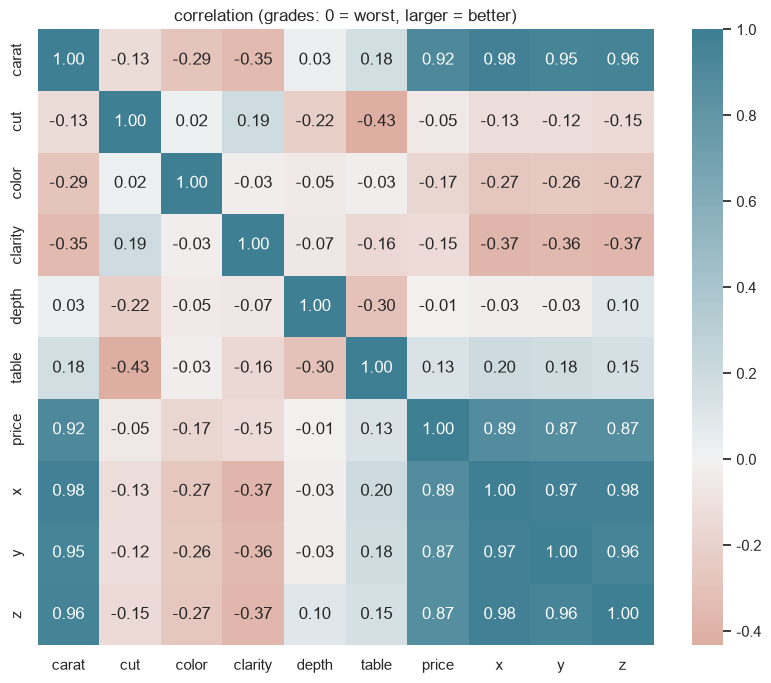

In [27]:
corr_df = encode_ordinal(data_df.drop(columns=['Unnamed: 0'], errors='ignore'))
corr_df = corr_df[(corr_df[['x', 'y', 'z']] > 0).all(axis=1)]
corrmat = corr_df.corr()

f, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corrmat, cmap=sns.diverging_palette(20, 220, as_cmap=True), center=0,
            annot=True, fmt='.2f', square=True, ax=ax)
ax.set_title('correlation (grades: 0 = worst, larger = better)'); plt.show()

**히트맵 읽기** (`price` 줄을 보세요)
- `carat`, `x`, `y`, `z`: 가격과 **0.86~0.92**로 매우 높은 상관 (원본 노트와 같음). 이 넷끼리도 0.95 이상 → 같은 정보.
- `cut`, `color`, `clarity`: 가격과 **음수(−0.05 ~ −0.17)**. "좋은 등급일수록 싸다"는 6장의 역설이 그대로 나타납니다.
  그리고 이 세 등급은 모두 `carat`과 **음수 상관**입니다 → "좋은 등급일수록 가볍다". 역설의 원인이 히트맵에도 보입니다.
- `depth`, `table`: 가격과 거의 0.

## 7-4 원본 노트 점검: "상관이 낮은 cut, clarity, depth는 빼도 된다?"

원본은 "cut, clarity, depth는 상관이 |0.1|보다 낮아 제거할 수도 있다"고 적었습니다.
6장에서 본 것처럼 **무게 효과에 가려진** 것일 수 있습니다. 확인 방법:

1. 무게만으로 가격을 예측하는 직선을 긋습니다 (로그 가격 ~ 로그 무게).
2. 실제 가격과 그 예측의 **차이(남은 가격)** 를 구합니다. = "무게로 설명하고 **남은** 가격"
3. 남은 가격과 각 등급의 상관을 봅니다.

In [28]:
from sklearn.linear_model import LinearRegression

log_carat = np.log(corr_df[['carat']])
log_price = np.log(corr_df['price'])
carat_only = LinearRegression().fit(log_carat, log_price)
leftover = log_price - carat_only.predict(log_carat)   # 무게로 설명하고 남은 (로그)가격

compare = pd.DataFrame({
    '가격과의 상관 (원본 방식)': corr_df[['cut', 'color', 'clarity', 'depth', 'table']].corrwith(corr_df['price']),
    '무게 효과를 뺀 뒤의 상관': corr_df[['cut', 'color', 'clarity', 'depth', 'table']].corrwith(leftover),
}).round(3)
display(compare)
print(f'무게(로그) 하나로 설명되는 로그 가격의 비율 R² = {carat_only.score(log_carat, log_price):.3f}')

,가격과의 상관 (원본 방식),무게 효과를 뺀 뒤의 상관
cut,-0.053,0.224
color,-0.172,0.371
clarity,-0.147,0.612
depth,-0.011,-0.110
table,0.127,-0.104


무게(로그) 하나로 설명되는 로그 가격의 비율 R² = 0.933


**결론:** 무게 효과를 빼고 나면 결과가 완전히 바뀝니다.
- `clarity`: −0.15 → **+0.61**. 등급이 좋을수록 비싸다는 **강한** 관계가 드러납니다.
- `color`: −0.17 → **+0.37**. 뚜렷한 관계.
- `cut`: −0.05 → +0.22. 약하지만 양의 관계.
- `depth`, `table`: −0.1 정도로 여전히 약합니다.

> **[원본 수정]** "상관이 낮으니 빼자"는 판단은 위험합니다. `clarity`를 뺐다면 두 번째로 중요한 정보를 버린 것이 됩니다.
> 상관계수는 **한 번에 두 열만** 보는 도구라 숨은 변수를 놓칩니다.
> (원본도 "특성이 적어서 빼지 않겠다"고 해서 결과적으로는 문제가 없었습니다.)

---
# 8. 데이터 정리

원본의 정리 규칙을 그대로 쓰되, **각 단계에서 몇 행이 지워지는지** 기록합니다. 그리고 중복 제거를 추가합니다.

| 단계 | 규칙 | 이유 |
|---|---|---|
| 1 | `Unnamed: 0` 열 삭제 | 행 번호 (2장) |
| 2 | x, y, z 중 0이 있는 행 삭제 | 기록 오류 (3-1) |
| 3 | 45 < depth < 75 | 원본 기준, 동떨어진 모양 비율 |
| 4 | 40 < table < 80 | 원본 기준 |
| 5 | x < 40, y < 40, 2 < z < 40 | 원본 기준, 말이 안 되는 크기 (3-2) |
| 6 | depth 공식 검산 차이 5 이상 삭제 | **추가**, 원본 규칙이 놓친 크기 오류 (3-3) |
| 7 | 완전 중복 행 삭제 | **추가**, 시험 문제 유출 방지 (3-4) |

In [29]:
steps = []
df = data_df.copy()
def log_step(name, new_df):
    steps.append({'단계': name, '남은 행': len(new_df), '이번에 지운 행': len(df) - len(new_df)})
    return new_df

steps.append({'단계': '0. 시작', '남은 행': len(df), '이번에 지운 행': 0})
df = log_step('1. Unnamed: 0 삭제', df.drop(columns=['Unnamed: 0'], errors='ignore'))
df = log_step('2. 크기 0 삭제', df[(df[['x', 'y', 'z']] > 0).all(axis=1)])
df = log_step('3. depth 45~75', df[(df['depth'] < 75) & (df['depth'] > 45)])
df = log_step('4. table 40~80', df[(df['table'] < 80) & (df['table'] > 40)])
df = log_step('5. x, y, z 범위', df[(df['x'] < 40) & (df['y'] < 40) & (df['z'] < 40) & (df['z'] > 2)])
print('원본 규칙까지 적용한 뒤 y, z 최대값:', df['y'].max(), df['z'].max(), '← 31.8 오류가 아직 남아 있음')
depth_gap = (df['z'] / ((df['x'] + df['y']) / 2) * 100 - df['depth']).abs()
df = log_step('6. depth 검산 (추가)', df[depth_gap < 5])
df = log_step('7. 중복 삭제 (추가)', df.drop_duplicates())
display(pd.DataFrame(steps))
clean_df = df.reset_index(drop=True)
print(f'최종: {clean_df.shape}  → 원래의 {len(clean_df) / len(data_df):.2%} 유지')

원본 규칙까지 적용한 뒤 y, z 최대값: 31.8 31.8 ← 31.8 오류가 아직 남아 있음


,단계,남은 행,이번에 지운 행
0,0. 시작,53940,0
1,1. Unnamed: 0 삭제,53940,0
2,2. 크기 0 삭제,53920,20
3,3. depth 45~75,53914,6
4,4. table 40~80,53913,1
5,"5. x, y, z 범위",53909,4
6,6. depth 검산 (추가),53889,20
7,7. 중복 삭제 (추가),53745,144


최종: (53745, 10)  → 원래의 99.64% 유지


**결론**
- 원본 규칙으로 31행이 빠지지만, **y = 31.8, z = 31.8인 행은 남습니다** (원본 기준이 40이라 31.8을 통과시킴).
  depth 공식 검산을 추가하면 이런 행이 걸러집니다. 이것이 **"값 하나만 보지 말고 열 사이의 관계로 확인하라"** 의 실제 효과입니다.
- 중복 144행까지 빼도 **99.6% 이상**의 데이터가 남습니다. 데이터가 많아 이 정도 삭제는 부담이 없습니다.

> **[원본 수정 — 작은 것]** 원본의 `data_df.drop(data_df[data_df["x"]==0].index)`처럼 x, y, z를 따로 세 번 지우는 대신
> `(df[['x','y','z']] > 0).all(axis=1)` 한 줄로 같은 일을 합니다.
>
> **주의:** 이 규칙은 학습/시험을 나누기 **전에** 전체 데이터로 정했습니다. 여기서는 "물리적으로 불가능한 값" 기준이라 괜찮지만,
> 평균이나 비율처럼 **데이터로 계산하는** 기준은 학습 데이터만 보고 정해야 합니다.

In [30]:
# 정리 후 기초 통계 — 0과 말이 안 되는 크기(58.9, 31.8)가 사라졌는지 확인
clean_df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
carat,53745.0,0.80,0.47,0.20,0.40,0.70,1.04,5.01
depth,53745.0,61.75,1.42,50.80,61.00,61.80,62.50,73.60
table,53745.0,57.46,2.23,43.00,56.00,57.00,59.00,79.00
price,53745.0,3930.39,3985.33,326.00,950.00,2401.00,5323.00,18823.00
x,53745.0,5.73,1.12,3.73,4.71,5.70,6.54,10.74
y,53745.0,5.73,1.11,3.68,4.72,5.71,6.54,10.54
z,53745.0,3.54,0.69,2.24,2.91,3.53,4.03,6.98


---
# 9. 모델링 — 원본의 모델 6종 비교

## 9-1 학습 / 시험 데이터 나누기

- **X**: 가격을 예측하는 데 쓰는 열 (9개), **y**: 맞힐 정답 (`price`)
- 80%로 공부(학습)하고, 20%는 **최종 시험용으로 봉인**합니다. 원본과 같은 `test_size=0.20, random_state=25`.
- 모델 비교와 조정은 학습 데이터 안에서 **교차검증**으로만 합니다. 시험 데이터는 12장에서 **단 한 번** 엽니다.

> **교차검증(Cross Validation)**: 학습 데이터를 5조각으로 나눠, 4조각으로 공부하고 1조각으로 쪽지시험을 보는 것을
> 조각을 바꿔 5번 반복해 평균을 냅니다. 한 번의 시험 운에 휘둘리지 않는 점수를 얻습니다.

In [31]:
from sklearn.model_selection import train_test_split, KFold, cross_validate

X_raw = clean_df.drop(columns=['price'])   # 아직 글자 등급 그대로
y = clean_df['price']
X_train_raw, X_test_raw, y_train, y_test = train_test_split(X_raw, y, test_size=0.20, random_state=25)

# 원본 방식 (LabelEncoder, 알파벳 순서) — 학습 데이터로만 번호표를 만들고 시험 데이터에도 같은 번호표 적용
label_maps = {col: {c: i for i, c in enumerate(sorted(X_train_raw[col].unique()))} for col in ORDERS}
def encode_label(df):
    out = df.copy()
    for col, m in label_maps.items():
        out[col] = out[col].map(m)
    return out

X_train_label, X_test_label = encode_label(X_train_raw), encode_label(X_test_raw)
X_train, X_test = encode_ordinal(X_train_raw), encode_ordinal(X_test_raw)   # 올바른 순서 인코딩

print('학습:', X_train.shape, '| 시험:', X_test.shape)
print('학습/시험 가격 평균:', round(y_train.mean()), '/', round(y_test.mean()), '→ 비슷하게 나뉨')
display(X_train.head(3))

학습: (42996, 9) | 시험: (10749, 9)
학습/시험 가격 평균: 3923 / 3962 → 비슷하게 나뉨


,carat,cut,color,clarity,depth,table,x,y,z
14147,1.06,4,4,2,62.1,57.0,6.53,6.51,4.05
21333,1.51,2,5,1,63.1,58.0,7.31,7.28,4.60
16127,1.00,3,4,3,62.4,60.0,6.38,6.35,3.97


## 9-2 모델 6종 — 한 줄 설명

| 모델 | 어떻게 예측하나 (한 줄) | 특징 |
|---|---|---|
| `LinearRegression` | 각 열에 가중치를 곱해 더한 **직선(평면)** | 단순·빠름. 휜 관계에 약함 |
| `Lasso` | 선형 회귀 + "쓸모없는 열의 가중치를 0으로 줄이기" | 열 고르기 효과 |
| `DecisionTree` | "carat ≤ 1.0?" 같은 **예/아니오 질문을 이어 가며** 구간별 평균 | 계단 모양을 잘 잡음. 외우기(과적합) 쉬움 |
| `RandomForest` | 조금씩 다른 나무 **수백 그루의 평균** | 나무 하나보다 안정적 |
| `KNeighbors` | 가장 **비슷한 다이아몬드 5개**의 평균 가격 | 열의 단위(스케일)를 맞춰야 함 |
| `XGB` / `HistGB` | 나무를 **차례로** 쌓아 앞 나무의 실수를 고침 (부스팅) | 표 데이터에서 보통 가장 강함 |

원본처럼 모든 모델을 `StandardScaler`(표준화)와 묶은 `Pipeline`으로 만듭니다.

> **표준화**: 각 열을 "평균 0, 표준편차 1"로 바꿔 단위를 맞추는 것. carat(0.2~5)과 table(43~79)처럼 단위가 다르면
> KNN의 "거리"가 큰 숫자 열에 휘둘리기 때문에 **KNN에는 꼭 필요**합니다. 나무 모델은 "크다/작다"만 보므로 필요 없지만 해도 해롭지 않습니다.

In [32]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.neighbors import KNeighborsRegressor

try:
    from xgboost import XGBRegressor
    BOOST_NAME = 'XGBRegressor'
    make_boost = lambda: XGBRegressor(random_state=SEED, n_jobs=-1)
except ImportError:
    BOOST_NAME = 'HistGB (XGB 대체)'
    make_boost = lambda: HistGradientBoostingRegressor(random_state=SEED)
print('부스팅 모델:', BOOST_NAME)

def make_pipelines():
    # 원본의 pipeline_lr ~ pipeline_xgb 와 같은 구성
    return {
        'LinearRegression': Pipeline([('scalar1', StandardScaler()), ('lr', LinearRegression())]),
        'Lasso': Pipeline([('scalar2', StandardScaler()), ('lasso', Lasso())]),
        'DecisionTree': Pipeline([('scalar3', StandardScaler()), ('dt', DecisionTreeRegressor(random_state=SEED))]),
        'RandomForest': Pipeline([('scalar4', StandardScaler()),
                                  ('rf', RandomForestRegressor(n_estimators=100, random_state=SEED, n_jobs=-1))]),
        'KNeighbors': Pipeline([('scalar5', StandardScaler()), ('kn', KNeighborsRegressor())]),
        BOOST_NAME: Pipeline([('scalar6', StandardScaler()), ('xgb', make_boost())]),
    }

CV = KFold(n_splits=5, shuffle=True, random_state=SEED)
SCORING = {'rmse': 'neg_root_mean_squared_error', 'mae': 'neg_mean_absolute_error', 'r2': 'r2',
           'pct': 'neg_mean_absolute_percentage_error'}

def cv_table(models, X, y_, title):
    rows = []
    for name, model in models.items():
        t0 = time.time()
        s = cross_validate(model, X, y_, cv=CV, scoring=SCORING, n_jobs=1)
        rows.append({'모델': name, 'RMSE': -s['test_rmse'].mean(), 'RMSE 흔들림(±)': s['test_rmse'].std(),
                     'MAE': -s['test_mae'].mean(), '% 오차': -s['test_pct'].mean() * 100,
                     'R²': s['test_r2'].mean(), '시간(초)': time.time() - t0})
        print(f'{title} | {name:18s} RMSE {rows[-1]["RMSE"]:8.1f}  ({rows[-1]["시간(초)"]:.0f}초)')
    return pd.DataFrame(rows).set_index('모델').round({'RMSE': 1, 'RMSE 흔들림(±)': 1, 'MAE': 1, '% 오차': 1, 'R²': 4, '시간(초)': 1})

부스팅 모델: HistGB (XGB 대체)


## 9-3 원본 방식(LabelEncoder) vs 올바른 순서 인코딩

**[원본 수정]** 원본은 12겹 교차검증을 썼습니다. 결과는 거의 같고 시간만 2배 이상 걸리므로 5겹으로 줄였습니다.
또 원본은 교차검증 전에 `pipe.fit(X_train, y_train)`을 한 번 더 했는데, `cross_val_score`는 내부에서 모델을 새로 학습하므로 그 단계는 필요 없습니다.

> 이 셀은 컴퓨터에 따라 1~3분 걸립니다 (RandomForest가 가장 오래 걸림).

In [33]:
cv_label = cv_table(make_pipelines(), X_train_label, y_train, 'LabelEncoder')
print()
cv_ordinal = cv_table(make_pipelines(), X_train, y_train, '순서 인코딩 ')

LabelEncoder | LinearRegression   RMSE   1331.2  (0초)


LabelEncoder | Lasso              RMSE   1334.5  (1초)


LabelEncoder | DecisionTree       RMSE    755.2  (2초)


LabelEncoder | RandomForest       RMSE    550.7  (31초)


LabelEncoder | KNeighbors         RMSE    821.1  (2초)


...

순서 인코딩  | Lasso              RMSE   1200.0  (1초)


순서 인코딩  | DecisionTree       RMSE    747.8  (1초)


순서 인코딩  | RandomForest       RMSE    545.5  (18초)


순서 인코딩  | KNeighbors         RMSE    719.5  (1초)


순서 인코딩  | HistGB (XGB 대체)    RMSE    537.4  (2초)


,RMSE (원본 LabelEncoder),RMSE (순서 인코딩),개선(달러)
모델,,,
LinearRegression,1331.2,1195.4,135.8
Lasso,1334.5,1200.0,134.5
DecisionTree,755.2,747.8,7.4
RandomForest,550.7,545.5,5.2
KNeighbors,821.1,719.5,101.6
HistGB (XGB 대체),547.3,537.4,9.9


순서 인코딩 결과 전체:


,RMSE,RMSE 흔들림(±),MAE,% 오차,R²,시간(초)
모델,,,,,,
LinearRegression,1195.4,22.4,791.0,42.8,0.9098,0.2
Lasso,1200.0,21.6,792.0,42.9,0.9091,0.6
DecisionTree,747.8,12.7,365.7,8.7,0.9647,1.0
RandomForest,545.5,12.7,271.9,6.6,0.9812,18.5
KNeighbors,719.5,15.9,379.8,10.5,0.9673,1.4
HistGB (XGB 대체),537.4,11.0,282.8,8.1,0.9818,2.0


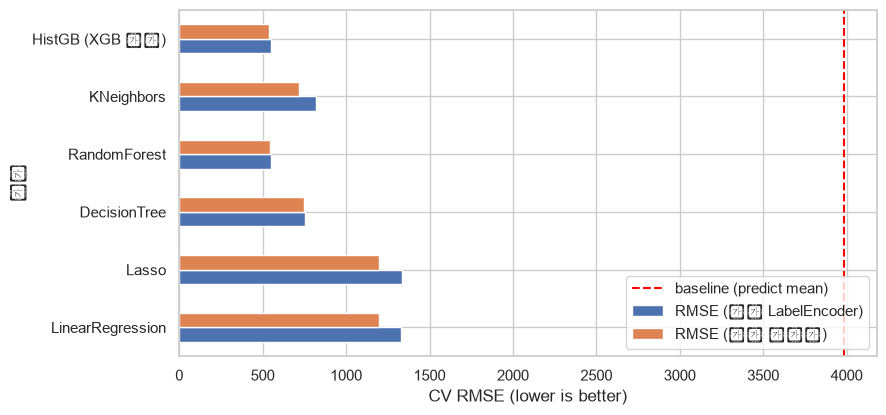

In [34]:
both = pd.DataFrame({'RMSE (원본 LabelEncoder)': cv_label['RMSE'], 'RMSE (순서 인코딩)': cv_ordinal['RMSE']})
both['개선(달러)'] = both['RMSE (원본 LabelEncoder)'] - both['RMSE (순서 인코딩)']
display(both.round(1))
print('순서 인코딩 결과 전체:'); display(cv_ordinal)

ax = both[['RMSE (원본 LabelEncoder)', 'RMSE (순서 인코딩)']].plot.barh(figsize=(9, 4.5))
ax.axvline(y_train.std(), color='red', linestyle='--', label='baseline (predict mean)')
ax.set_xlabel('CV RMSE (lower is better)'); ax.legend(loc='lower right'); plt.show()

**결과 읽기**
- **모든 모델이 기준선(빨간 선, 약 4,000달러)보다 훨씬 좋습니다.**
- 선형 모델(LinearRegression, Lasso)은 RMSE 약 1,200달러로 가장 약합니다. 5장에서 본 **휜 관계**를 직선으로 못 따라가기 때문입니다.
- 나무 계열(RandomForest, 부스팅)은 RMSE 약 540달러로 가장 좋습니다. 원본도 XGB가 가장 좋았습니다.
- **순서 인코딩**은 선형 모델과 KNN을 크게 개선합니다(RMSE 100달러 이상 감소). 나무 모델은 갈림길을 여러 번 만들어 엉터리 순서를 스스로 극복하므로 차이가 작습니다.

> **"RMSE 흔들림(±)"** 은 5번의 쪽지시험 점수가 얼마나 들쭉날쭉했는지입니다. 두 모델의 RMSE 차이가 이 흔들림보다 작으면
> "확실히 더 좋다"고 말하기 어렵습니다.

---
# 10. 가격에 로그 씌우기 — 같은 모델, 더 좋은 점수

4장과 5장에서 본 두 가지:
1. 가격은 오른쪽으로 긴 꼬리를 가진다 → 로그를 씌우면 고른 모양
2. 무게와 가격은 휜 관계 → 둘 다 로그를 씌우면 직선

**가설:** 로그 가격으로 학습하고, 예측한 뒤 다시 원래 달러로 되돌리면(지수 함수 `exp`) 특히 선형 회귀가 크게 좋아질 것이다.

> `TransformedTargetRegressor`는 "학습할 때는 log(가격)으로, 예측을 내놓을 때는 exp로 되돌려서" 를 자동으로 해 주는 포장지입니다.
> 점수는 **원래 달러 기준**으로 계산되므로 9장 결과와 바로 비교할 수 있습니다.

In [35]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.preprocessing import FunctionTransformer
from sklearn.compose import ColumnTransformer

def log_target(model):
    return TransformedTargetRegressor(regressor=model, func=np.log, inverse_func=np.exp)

# 선형 회귀는 입력의 carat에도 로그를 씌워야 직선 관계가 됩니다 (5-1의 오른쪽 그림)
log_carat_step = ColumnTransformer([('log', FunctionTransformer(np.log), ['carat'])], remainder='passthrough')

log_models = {
    'LinearRegression (log 가격 + log carat)': log_target(
        Pipeline([('logc', log_carat_step), ('sc', StandardScaler()), ('lr', LinearRegression())])),
    'KNeighbors (log 가격)': log_target(Pipeline([('sc', StandardScaler()), ('kn', KNeighborsRegressor())])),
    f'{BOOST_NAME} (log 가격)': log_target(make_boost()),
}
cv_log = cv_table(log_models, X_train, y_train, 'log')
display(cv_log)

log | LinearRegression (log 가격 + log carat) RMSE    961.3  (0초)


log | KNeighbors (log 가격) RMSE    722.7  (1초)


log | HistGB (XGB 대체) (log 가격) RMSE    548.3  (2초)


,RMSE,RMSE 흔들림(±),MAE,% 오차,R²,시간(초)
모델,,,,,,
LinearRegression (log 가격 + log carat),961.3,29.6,460.7,11.4,0.9416,0.2
KNeighbors (log 가격),722.7,15.0,380.3,10.3,0.9670,1.4
HistGB (XGB 대체) (log 가격),548.3,12.0,278.4,6.7,0.9810,2.1


In [36]:
lr_raw = make_pipelines()['LinearRegression'].fit(X_train, y_train)
print('그냥 선형 회귀가 학습 데이터에서 내놓은 음수 가격 예측:', (lr_raw.predict(X_train) < 0).sum(), '개')
print('최저 예측 가격:', round(lr_raw.predict(X_train).min()), '달러')
print('로그 가격 모델은 exp로 되돌리므로 음수 예측이 원리상 불가능합니다.')

그냥 선형 회귀가 학습 데이터에서 내놓은 음수 가격 예측: 3456 개
최저 예측 가격: -2917 달러
로그 가격 모델은 exp로 되돌리므로 음수 예측이 원리상 불가능합니다.


**결론**
- 선형 회귀: RMSE 약 1,200 → 약 **960달러**, % 오차는 **43% → 11%** 로 크게 좋아집니다. 같은 "직선 모델"인데, 데이터를 직선이 맞는 모양으로 바꿔 주었기 때문입니다.
- 그냥 선형 회귀는 학습 데이터의 약 8%에 **음수 가격**(최저 약 −2,900달러)을 예측했습니다. 로그 모델은 이런 말이 안 되는 예측을 하지 않습니다.
- 부스팅은 **RMSE는 거의 같지만(약 537 → 548) % 오차가 8.1% → 6.7%로 줄어듭니다.** (KNN은 거의 차이 없음) 로그 가격으로 배우면 "몇 달러"보다 "몇 %" 틀리는지를 줄이는 쪽으로 배우기 때문입니다.
  싼 다이아몬드를 10% 틀리는 것과 비싼 다이아몬드를 10% 틀리는 것을 같은 무게로 봅니다.

> **지표에 따라 승자가 달라질 수 있습니다.** RMSE만 보면 로그 변환이 부스팅에 도움이 안 되는 것처럼 보이지만, % 오차로 보면 도움이 됩니다.
> 12장에서 이 차이를 가격대별로 확인합니다.

> **핵심:** 모델을 바꾸기 전에 **데이터를 모델이 이해하기 쉬운 모양으로** 바꾸는 것만으로도 큰 향상이 생깁니다.
> 그리고 이 아이디어는 4~5장의 EDA(그림 보기)에서 나왔습니다.

---
# 11. 과적합 이해하기와 간단한 조정

## 11-1 의사결정나무의 깊이와 과적합

**과적합**: 학습 데이터를 **외워 버려서** 학습 점수는 아주 좋은데 새 데이터 점수는 나쁜 상태입니다.
의사결정나무는 질문을 무한히 이어 가면(깊이 제한 없음) 학습 데이터를 거의 완벽하게 외웁니다.

,max_depth,학습 RMSE,검증 RMSE
0,2,1645.0,1648.0
1,4,1149.0,1157.0
2,6,844.0,862.0
3,8,658.0,706.0
4,10,528.0,639.0
5,12,425.0,650.0
6,15,278.0,701.0
7,20,97.0,745.0
8,30,9.0,750.0


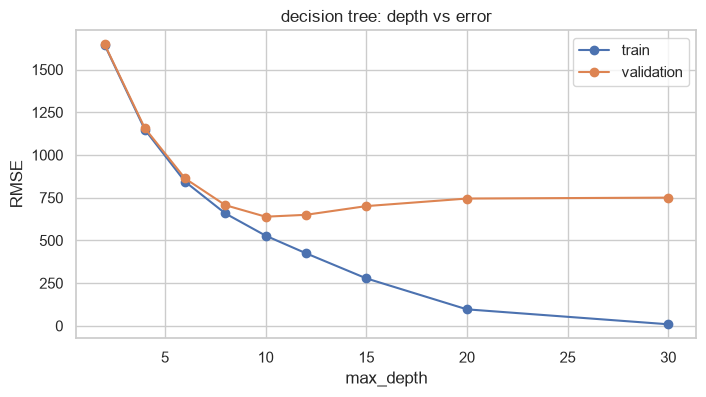

In [37]:
from sklearn.model_selection import validation_curve

depths = [2, 4, 6, 8, 10, 12, 15, 20, 30]
train_s, valid_s = validation_curve(DecisionTreeRegressor(random_state=SEED), X_train, y_train,
                                    param_name='max_depth', param_range=depths, cv=CV,
                                    scoring='neg_root_mean_squared_error', n_jobs=-1)
curve = pd.DataFrame({'max_depth': depths, '학습 RMSE': -train_s.mean(axis=1), '검증 RMSE': -valid_s.mean(axis=1)})
display(curve.round(0))

plt.plot(depths, -train_s.mean(axis=1), marker='o', label='train')
plt.plot(depths, -valid_s.mean(axis=1), marker='o', label='validation')
plt.xlabel('max_depth'); plt.ylabel('RMSE'); plt.title('decision tree: depth vs error'); plt.legend(); plt.show()

**그림 읽기**
- 깊이가 얕으면(2~4) 학습·검증 오차가 **모두 큽니다** → 너무 단순함(덜 배움)
- 깊어질수록 둘 다 줄다가, 어느 지점부터 **학습 오차는 계속 0을 향해 가는데 검증 오차는 더 줄지 않거나 다시 커집니다** → 외우기 시작(과적합)
- 9장의 `DecisionTree`는 깊이 제한이 없어서 이 그래프의 오른쪽 끝에 해당합니다.

> **랜덤 포레스트와 부스팅이 나무 하나보다 좋은 이유:** 외워 버린 나무 여러 그루를 **평균** 내면(포레스트) 각 나무의 엉뚱한 외우기가 서로 상쇄되고,
> 작은 나무를 **차례로** 쌓으면(부스팅) 조금씩 실수를 고쳐 나가므로 외우기가 덜합니다.

## 11-2 부스팅 모델 간단 조정

부스팅 모델의 대표적인 조정 값 두 가지만 바꿔 봅니다. (학습 데이터 안의 교차검증으로만 비교)
- **나무 개수(학습 횟수)**: 많을수록 더 꼼꼼히 배우지만 오래 걸림
- **학습률**: 한 번에 얼마나 크게 고칠지. 작으면 천천히 꼼꼼하게, 크면 빠르지만 거칠게

In [38]:
from sklearn.model_selection import GridSearchCV

if BOOST_NAME == 'XGBRegressor':
    grid = {'regressor__n_estimators': [300, 600], 'regressor__learning_rate': [0.05, 0.1],
            'regressor__max_depth': [6, 8]}
else:
    grid = {'regressor__max_iter': [300, 600], 'regressor__learning_rate': [0.05, 0.1],
            'regressor__max_leaf_nodes': [31, 63]}

t0 = time.time()
search = GridSearchCV(log_target(make_boost()), grid, cv=CV, scoring='neg_root_mean_squared_error', n_jobs=-1)
search.fit(X_train, y_train)
print(f'{time.time() - t0:.0f}초 걸림')
res = pd.DataFrame(search.cv_results_)
res = res[[c for c in res.columns if c.startswith('param_')] + ['mean_test_score', 'std_test_score']]
res['RMSE'] = -res.pop('mean_test_score'); res['흔들림(±)'] = res.pop('std_test_score')
display(res.sort_values('RMSE').round({'RMSE': 1, '흔들림(±)': 1}))
print('가장 좋은 조합:', search.best_params_, '| CV RMSE', round(-search.best_score_, 1))

29초 걸림


,param_regressor__learning_rate,param_regressor__max_iter,param_regressor__max_leaf_nodes,RMSE,흔들림(±)
1,0.05,300,63,532.9,9.5
3,0.05,600,63,533.3,10.7
2,0.05,600,31,533.9,9.7
7,0.10,600,63,534.0,11.2
5,0.10,300,63,534.0,11.2
6,0.10,600,31,536.4,9.3
4,0.10,300,31,537.2,9.8
0,0.05,300,31,538.7,9.9


가장 좋은 조합: {'regressor__learning_rate': 0.05, 'regressor__max_iter': 300, 'regressor__max_leaf_nodes': 63} | CV RMSE 532.9


**결론:** 기본값(10장, RMSE 약 550)보다 15달러 정도 좋아지지만, 조합 사이의 차이는 대부분 흔들림(±) 범위와 비슷한 수십 달러 수준입니다.
**큰 향상은 데이터 정리·인코딩·로그 변환에서 나왔고, 조정은 마무리 손질**입니다. 실전에서도 흔한 패턴입니다.

### 지금까지의 교차검증 점수 한눈에 보기

In [39]:
summary = pd.concat([
    pd.Series({'평균으로 찍기 (기준선)': y_train.std()}),
    cv_label['RMSE'].rename(lambda n: f'{n} [원본: LabelEncoder]'),
    cv_ordinal['RMSE'].rename(lambda n: f'{n} [순서 인코딩]'),
    cv_log['RMSE'],
    pd.Series({f'{BOOST_NAME} (log 가격, 조정)': -search.best_score_}),
]).sort_values()
display(summary.round(1).to_frame('CV RMSE (달러)'))

,CV RMSE (달러)
"HistGB (XGB 대체) (log 가격, 조정)",532.9
HistGB (XGB 대체) [순서 인코딩],537.4
RandomForest [순서 인코딩],545.5
HistGB (XGB 대체) [원본: LabelEncoder],547.3
HistGB (XGB 대체) (log 가격),548.3
RandomForest [원본: LabelEncoder],550.7
KNeighbors [순서 인코딩],719.5
KNeighbors (log 가격),722.7
DecisionTree [순서 인코딩],747.8
DecisionTree [원본: LabelEncoder],755.2


---
# 12. 최종 평가 — 시험 데이터로 단 한 번

교차검증에서 가장 좋았던 **조정된 부스팅 모델(로그 가격)** 을 학습 데이터 전체로 다시 학습하고, 봉인해 둔 시험 데이터로 채점합니다.
원본처럼 **R²** 와 **조정된 R²** 도 함께 계산합니다.

> **조정된 R²(Adjusted R²)**: 쓸모없는 열을 많이 넣을수록 R²가 조금씩 올라가는 것을 막기 위해 **열 개수만큼 벌점**을 준 R²입니다.
> 데이터가 1만 개 이상이고 열이 9개뿐이면 R²와 거의 같습니다.

In [40]:
from sklearn import metrics

final_model = search.best_estimator_   # GridSearchCV가 학습 데이터 전체로 이미 다시 학습해 둠
pred = final_model.predict(X_test)

r2 = metrics.r2_score(y_test, pred)
n, p = X_test.shape
adj_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)      # 원본과 같은 공식
rmse = metrics.mean_squared_error(y_test, pred) ** 0.5
mae = metrics.mean_absolute_error(y_test, pred)
pct = (np.abs(y_test - pred) / y_test).mean() * 100

print(f'최종 모델: {BOOST_NAME} (log 가격, 조정)')
print(f'R²            = {r2:.4f}')
print(f'Adjusted R²   = {adj_r2:.4f}')
print(f'RMSE          = {rmse:,.0f} 달러')
print(f'MAE           = {mae:,.0f} 달러')
print(f'평균 % 오차   = {pct:.1f}%   (가격 대비 평균적으로 몇 % 틀리나)')

최종 모델: HistGB (XGB 대체) (log 가격, 조정)
R²            = 0.9821
Adjusted R²   = 0.9820
RMSE          = 536 달러
MAE           = 265 달러
평균 % 오차   = 6.2%   (가격 대비 평균적으로 몇 % 틀리나)


**결과 해석**
- R² 약 0.98 — 원본(0.9827)과 비슷합니다. 평균으로 찍는 것보다 오차(제곱)를 98% 이상 줄였습니다.
- 평균적으로 **약 265달러**, 가격 대비 **약 6%** 틀립니다. 교차검증 RMSE(약 533)와 시험 RMSE(약 536)가 거의 같습니다.
- 교차검증 RMSE와 시험 RMSE가 비슷하면, 모델이 학습 데이터를 외운 것이 아니라 **새 데이터에도 통한다**는 증거입니다.

> 이 점수가 의미 있는 이유는 시험 데이터를 **모델 선택·조정에 한 번도 쓰지 않았기** 때문입니다.
> 시험 점수를 보고 모델을 다시 고치면, 그 순간부터 시험 데이터도 "공부한 문제"가 됩니다.

## 12-1 예측 vs 실제

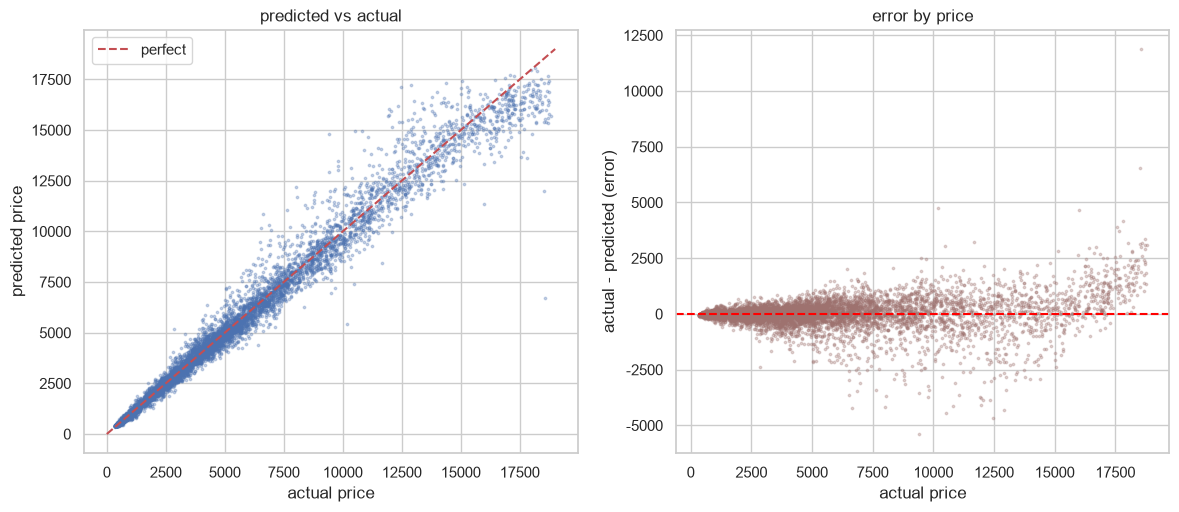

In [41]:
f, ax = plt.subplots(1, 2, figsize=(14, 5.5))
ax[0].scatter(y_test, pred, s=3, alpha=0.3)
ax[0].plot([0, 19000], [0, 19000], 'r--', label='perfect')
ax[0].set_xlabel('actual price'); ax[0].set_ylabel('predicted price'); ax[0].set_title('predicted vs actual'); ax[0].legend()
ax[1].scatter(y_test, y_test - pred, s=3, alpha=0.3, color='#9E726F')
ax[1].axhline(0, color='red', linestyle='--')
ax[1].set_xlabel('actual price'); ax[1].set_ylabel('actual - predicted (error)'); ax[1].set_title('error by price')
plt.show()

**그림 읽기**
- 왼쪽: 점들이 빨간 대각선(완벽한 예측) 주변에 모여 있습니다.
- 오른쪽: 가격이 비쌀수록 오차가 **나팔처럼 넓게** 퍼집니다. 1,000달러짜리는 수십 달러, 15,000달러짜리는 수천 달러 틀립니다.

**가설:** 달러로는 비싼 다이아몬드에서 많이 틀리지만, **비율(%)** 로 보면 비슷할 것이다.

In [42]:
band = pd.cut(y_test, [0, 1000, 2500, 5000, 10000, 20000],
              labels=['~1k', '1k~2.5k', '2.5k~5k', '5k~10k', '10k~'])
err = pd.DataFrame({'band': band, 'abs_err': (y_test - pred).abs(), 'pct_err': (y_test - pred).abs() / y_test * 100})
by_band = err.groupby('band', observed=True).agg(개수=('abs_err', 'size'), 평균오차_달러=('abs_err', 'mean'),
                                                  평균오차_퍼센트=('pct_err', 'mean')).round(1)
display(by_band)

,개수,평균오차_달러,평균오차_퍼센트
band,,,
~1k,2879,36.9,5.3
1k~2.5k,2603,98.7,6.0
2.5k~5k,2260,240.3,6.6
5k~10k,1961,494.1,7.1
10k~,1046,934.5,6.8


**결론:** 달러 오차는 가격대가 높을수록 수십 배 커지지만, **% 오차는 가격대와 관계없이 비슷한 수준**입니다.
"가격의 몇 % 정도 틀리는 모델"이라고 설명하는 것이 정직합니다.

> RMSE 하나만 보면 비싼 다이아몬드의 큰 달러 오차가 점수를 대부분 결정합니다. **어떤 지표로 평가할지는 문제의 목적에 따라** 정해야 합니다.
> (예: 보석상이 원하는 것이 "모든 가격대에서 고르게 정확한" 것이라면 % 오차가 더 맞는 기준입니다.)

---
# 13. 모델 해석 — 무엇이 가격을 정하나

## 13-1 섞어보기 중요도 (Permutation Importance)

**아이디어:** 어떤 열의 값을 **무작위로 섞어** 쓸모없게 만들었을 때 점수가 얼마나 나빠지는지 봅니다.
많이 나빠지면 → 모델이 그 열에 크게 의존한다 = 중요한 열.

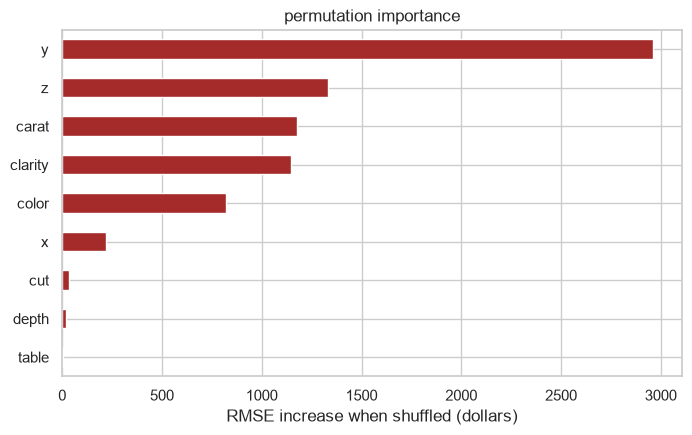

,섞었을 때 RMSE 증가(달러)
y,2959.0
z,1332.0
carat,1175.0
clarity,1147.0
color,822.0
x,221.0
cut,32.0
depth,21.0
table,4.0


In [43]:
from sklearn.inspection import permutation_importance

idx = X_test.sample(5000, random_state=SEED).index
imp = permutation_importance(final_model, X_test.loc[idx], y_test.loc[idx], n_repeats=5,
                             random_state=SEED, scoring='neg_root_mean_squared_error', n_jobs=-1)
imp_s = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()
imp_s.plot.barh(figsize=(8, 4.5), color='#A52A2A')
plt.xlabel('RMSE increase when shuffled (dollars)'); plt.title('permutation importance'); plt.show()
display(imp_s.sort_values(ascending=False).round(0).to_frame('섞었을 때 RMSE 증가(달러)'))

**결론**
- **무게 정보**(`carat`, `y`, `x`, `z`)가 가장 중요합니다. 이 넷은 같은 정보라 서로 나눠 가지므로 하나하나는 작게 보일 수 있습니다.
- 그다음은 **`clarity`, `color`** 입니다. 7-4에서 "무게 효과를 빼면 강한 관계"로 나온 두 열입니다. 원본 노트의 "clarity는 상관이 낮아 제거 후보"와 정반대 결과입니다.
- `cut`은 작고, `depth`, `table`은 거의 0입니다. 5-3, 7-4의 결론과 같습니다.

**EDA에서 세운 결론이 모델 해석과 일치합니다.** 그림과 표로 데이터를 이해한 내용을 모델이 확인해 준 셈입니다.

## 13-2 "만약에" 실험 — 같은 다이아몬드, 등급만 바꾸기

시험 데이터에서 1캐럿 근처의 다이아몬드 하나를 골라, **다른 열은 그대로 두고** 투명도만 바꿔 가며 예측 가격을 봅니다.

기준 다이아몬드 (cut 4 = Ideal, color 3 = G, clarity 2 = SI1):


,carat,cut,color,clarity,depth,table,x,y,z
13752,1.0,4,3,2,61.0,57.0,6.47,6.44,3.94


clarity  {'I1': 3124, 'SI2': 4267, 'SI1': 4989, 'VS2': 6360, 'VS1': 7019, 'VVS2': 7972, 'VVS1': 8463, 'IF': 8687}
color    {'J': 3943, 'I': 4352, 'H': 4864, 'G': 4989, 'F': 5330, 'E': 5552, 'D': 5790}
cut      {'Fair': 4537, 'Good': 4690, 'Very Good': 4798, 'Premium': 4750, 'Ideal': 4989}


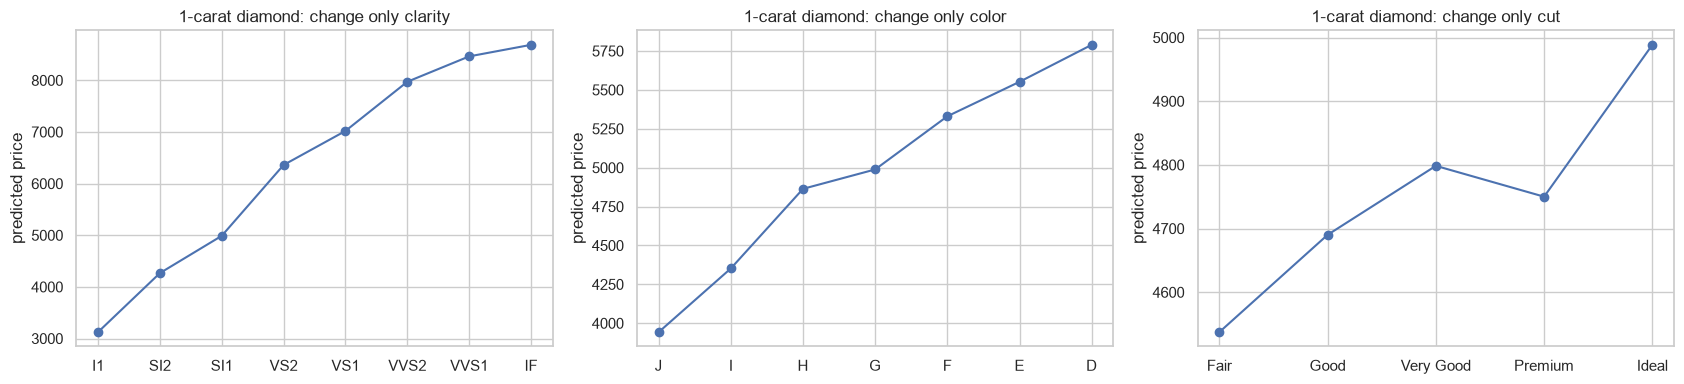

In [44]:
one = X_test[(X_test['carat'].between(0.99, 1.01)) & (X_test['clarity'] == 2) & (X_test['color'] == 3)
             & (X_test['cut'] == 4)].iloc[[0]]
print('기준 다이아몬드 (cut 4 = Ideal, color 3 = G, clarity 2 = SI1):'); display(one)

what_if = []
for col in ['clarity', 'color', 'cut']:
    for code_, grade in enumerate(ORDERS[col]):
        d = one.copy(); d[col] = code_
        what_if.append({'바꾼 열': col, '등급': grade, '예측 가격': final_model.predict(d)[0]})
what_if = pd.DataFrame(what_if)
for col in ['clarity', 'color', 'cut']:
    w = what_if[what_if['바꾼 열'] == col]
    print(f'{col:8s}', dict(zip(w['등급'], w['예측 가격'].round(0).astype(int))))

f, ax = plt.subplots(1, 3, figsize=(17, 4))
for i, col in enumerate(['clarity', 'color', 'cut']):
    w = what_if[what_if['바꾼 열'] == col]
    ax[i].plot(w['등급'], w['예측 가격'], marker='o')
    ax[i].set_title(f'1-carat diamond: change only {col}'); ax[i].set_ylabel('predicted price')
plt.tight_layout(); plt.show()

**결론:** 같은 1캐럿 다이아몬드에서 등급만 좋게 바꾸면 예측 가격이 **올라갑니다.**
- `clarity`: I1 약 3,100 → IF 약 8,700달러 (**약 2.8배**) — 효과가 가장 큼
- `color`: J 약 3,900 → D 약 5,800달러 (약 1.5배)
- `cut`: Fair 약 4,500 → Ideal 약 5,000달러 (약 10%) — 효과가 가장 작음


6-2에서 본 "나쁜 등급이 더 비싸다"는 역설이 모델 안에서는 일어나지 않습니다. 모델은 무게와 등급을 **동시에** 보기 때문입니다.

## 13-3 가장 크게 틀린 다이아몬드

In [45]:
worst = X_test_raw.copy()
worst['실제 가격'] = y_test; worst['예측 가격'] = pred.round(0)
worst['% 오차'] = ((worst['실제 가격'] - worst['예측 가격']).abs() / worst['실제 가격'] * 100).round(1)
display(worst.sort_values('% 오차', ascending=False).head(8))

,carat,cut,color,clarity,depth,table,x,y,z,실제 가격,예측 가격,% 오차
659,1.27,Premium,H,SI2,59.3,61.0,7.12,7.05,4.20,2845,5205.0,83.0
27546,2.01,Fair,G,SI1,70.6,64.0,7.43,6.64,4.69,18574,6690.0,64.0
16547,1.91,Fair,H,SI2,64.6,56.0,7.76,7.70,4.99,6632,10846.0,63.5
21208,1.65,Ideal,G,VS2,62.2,55.0,7.60,7.57,4.72,9425,14811.0,57.1
16335,1.27,Ideal,E,VS2,61.8,55.0,7.03,6.92,4.31,6543,10161.0,55.3
19255,1.61,Premium,F,SI1,62.9,59.0,7.50,7.43,4.69,8024,12201.0,52.1
17140,2.72,Fair,J,I1,68.2,56.0,8.46,8.43,5.76,6870,10338.0,50.5
3069,1.24,Ideal,J,SI1,62.3,57.0,6.86,6.81,4.26,3312,4957.0,49.7


**오답 살펴보기:** % 오차가 가장 큰 다이아몬드들은 대개
- 같은 조건의 다른 다이아몬드보다 **유난히 싸거나 비싸게** 팔린 경우이거나,
- 학습 데이터에 비슷한 예가 **거의 없는** 조합(아주 무겁거나, 드문 등급 조합)입니다.

데이터에 없는 정보(감정서 유무, 형광성, 판매처, 판매 시기 등)가 가격에 영향을 주었을 수 있습니다.
**모든 오차를 모델 탓으로 돌릴 수는 없습니다.** 데이터가 담지 못한 정보의 한계도 있습니다.

---
# 14. 정리

## 원본 대비 바뀐 점

| 원본 | 문제 | 이 노트북 |
|---|---|---|
| `LabelEncoder`로 등급 변환 | **알파벳 순서**라 Ideal < Premium, I1과 IF가 이웃 | 품질 순서를 직접 정해 순서 인코딩 (7장) → 선형·KNN 크게 개선 |
| "cut, clarity는 상관이 낮아 제거 후보" | 무게에 가려진 관계를 놓침 | 무게 효과를 빼면 clarity·color가 강한 관계 (7-4), 중요도 상위 (13-1) |
| 바이올린 그림을 알파벳 순서로 | 등급 흐름을 읽기 어려움, "나쁜 등급이 비싸다" 역설 미설명 | 등급 순서로 정렬 + 같은 무게끼리 비교로 역설 해설 (6장) |
| 크기 범위 기준 x, y, z < 40 | y = 31.8, z = 31.8 오류 행이 통과 | depth 공식 검산 추가 (3-3, 8장) |
| 중복 확인 없음 | 중복 행 → 학습/시험에 같은 다이아몬드가 들어갈 수 있음 | 중복 제거 (8장) |
| 원래 가격 그대로 학습 | 휜 관계·긴 꼬리 → 선형 모델 약함, 음수 가격 예측 | 로그 가격 학습 (10장) → 선형 RMSE 약 20% 감소, % 오차 43% → 11% |
| "98.27% **accuracy**" | 회귀에는 정확도가 없음, R²를 잘못 부름 | R², RMSE, MAE, % 오차를 함께 보고 (12장) |
| `scale="count"`, `palette` 단독 사용 | 최신 seaborn에서 경고·변경 | `density_norm`, `hue` 사용 |
| `xgboost` 필수 | 설치 안 된 환경에서 오류 | 없으면 scikit-learn 부스팅으로 대체 |

## 이 노트북에서 배운 것

1. **비어 있지 않다고 깨끗한 것은 아니다.** 크기 0, 58.9 mm 같은 값은 다른 열과 비교하고 공식으로 검산해서 찾는다.
2. **평균 > 중앙값이면 오른쪽 꼬리가 길다.** 이런 값에는 로그가 잘 맞는다.
3. **한 변수만 보면 정반대 결론이 나올 수 있다.** "나쁜 등급이 비싸다"의 진짜 원인은 숨은 변수(무게)였다. 조건을 맞추고 비교한다.
4. **글자를 숫자로 바꿀 때 순서를 지켜라.** `LabelEncoder`는 알파벳 순서다.
5. **상관계수가 낮다고 쓸모없는 열은 아니다.**
6. **모델을 바꾸기 전에 데이터를 바꿔 보라.** 로그 변환 하나로 선형 회귀가 크게 좋아졌다.
7. **시험 데이터는 마지막에 한 번만.** 비교와 조정은 교차검증으로.
8. **점수는 여러 개로 본다.** R² 0.98이라도 달러로는 수천 달러 틀리는 가격대가 있다. % 오차가 더 공정할 때가 있다.

## 더 해 볼 것 (과제)

- `x * y * z`(부피)를 새 열로 만들어 넣고 선형 회귀 점수가 바뀌는지 확인하기
- 13-1에서 중요도가 거의 0인 `depth`, `table`을 빼고 다시 학습해 점수 비교하기
- 평가 지표를 % 오차로 바꾸면 가장 좋은 모델이 달라지는지 확인하기